<a href="https://colab.research.google.com/github/Paulette-max/SemProject_MLEngine/blob/main/K_means_Base.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ICS 3202: Artificial Intelligence
## Semester Project: ICS 3B
### AI-Based Coffee Recommender Application
**Group Four**

**Group Members**
- Paulette Mbaika - 190016
- Brian Sanaet - 189718
- Stacy Njoki - 160077

**AI Application:** Coffee Recommender Application(mobile application with an ML engine)
**Algorithm/Approach:** Unsupervised learning, K-Means clustering, with similarity-based recommendation


## Summary

Choosing a drink at a busy coffee bar is harder than it looks. We surveyed a barista at the Strathmore University coffee bar (Nairobi, 21 September 2026), who told us that verbal recommendations take time when there are many customers and some are still unsure what to order. The main cost is unhappy customers, and those in a rush are the most affected. Research on choice difficulty supports this: extensive choice can reduce motivation to choose and satisfaction with the choice (Iyengar & Lepper, 2000).

Our project asks whether an AI, taste-based mobile recommender can match customers to drinks they are satisfied with, compared with barista advice. A customer states their tastes (for example sweetness, milk, strength), the ML engine ranks the menu against them, and the suggestion appears on their phone while they are still in the queue.

This notebook builds the ML engine. K-Means groups drinks with similar taste profiles. A similarity measure then ranks the drinks closest to the customer's stated tastes. The notebook follows the CRISP-DM process. It covers Phase 1 (Business Understanding) and Phase 2 (Data Understanding), then continues with data preparation, modelling and validation.


## Phase 1: Business Understanding

**1.1 Business objectives**
- Help customers choose a drink faster and with more confidence.
- Reduce the time baristas spend giving verbal recommendations at peak hours.
- Leave customers satisfied with the drink they ordered.

**1.2 Situation assessment**
- *Stakeholder:* a barista at the Strathmore University coffee bar (Industry pillar of the QuadHelix).
- *Who is affected:* time-pressed customers, especially students in a rush, and the staff advising them.
- *Alternatives considered and not chosen:* menu redesign (static, no personalisation), staff training (does not scale at peak hours), a static quiz or flowchart (fixed rules, cannot take free-text tastes), and a generic coffee chatbot (no preference profile or local menu).
- *Out of scope:* payments and POS integration, inventory forecasting, rollout across multiple shops, and health or nutrition advice.
- *Key risk:* a mismatch between the recommended drink and what the customer actually wants.

**1.3 Problem statement**
Customers at university coffee bars struggle to choose drinks quickly, and it is unknown how well an AI, taste-based mobile recommender can match them to satisfying drinks compared with barista advice.

**1.4 Data mining goals**
- Group drinks (and coffees) into clusters with similar taste profiles, using K-Means.
- Take a customer's stated tastes and return the closest matching drinks, ranked by similarity.
- Support optional filters (hot or iced, no milk, caffeine limit) so suggestions fit the customer's needs.

**1.5 Success criteria for the ML engine**
- Clusters are well separated and meaningful, checked with the elbow method and the silhouette score.
- Recommendations behave as expected on sanity checks, for example 'strong, no milk' returns espresso-style drinks.
- Later phases compare K-Means against other clustering models. Customer satisfaction against barista advice is tested after deployment.

**1.6 Project plan**
Business Understanding, Data Understanding, Data Preparation, Modelling, Evaluation, Deployment (the mobile app).


## Phase 2: Data Understanding

**2.1 Data collected**
We worked with two datasets:

| Dataset | Rows | Description |
| --- | --- | --- |
| `coffee_clean.csv` | 2,440 | Coffee reviews (the `slug` column links to coffeereview.com). 20 columns, including roaster, origin, roast, price and a rating (80-98). Five taste scores (aroma, acid, body, flavor, aftertaste) run from 5 or 6 to 10. |
| `coffee_drinks.csv` | 27 | Coffee-shop menu drinks, each with a category, temperature and flavour notes. Eight numeric features: strength, milk %, foam, acidity, bitterness, sweetness, body and caffeine (mg). |

**2.2 Data description**
- The five taste scores in `coffee_clean.csv` are the features K-Means learns from.
- The drinks features use fixed scales (1-5 for most, 0-5 for foam, 0-100 for milk %, 0-160 for caffeine).
- `est_price` and `agtron` are stored as text and would need converting before numeric use.

**2.3 Data exploration**
1. Taste scores are bunched at the top: the median and upper quartile for aroma, acid, body and flavor are 8 or 9.
2. Ratings are high and tight (mean 93, standard deviation 1.7), so these are mostly high-quality coffees.
3. Aftertaste scores lowest (mean 8.10 against 8.95 for flavor), and flavor is the most uniform (standard deviation 0.37).
4. `with_milk` is about 87% empty (2,115 of 2,440 rows), so it is excluded from modelling.
5. In the drinks data, features move together in sensible ways, for example milky drinks are sweeter and less strong (see the correlation heatmap).

**2.4 Data quality verification**
- *Duplicates:* none in the coffee reviews.
- *Missing values:* `roast` (58), `est_price` (6), `desc_1` (1), `desc_3` (1) and `with_milk` (2,115). The five taste features have none. The drinks dataset has none.
- *Outliers:* the boxplots show a few low scores. They are kept, because they are genuine reviews.
- *Limitations:* the taste scores are whole numbers, so many coffees share identical profiles and produce tied similarity scores. The drinks dataset has only 27 rows, which limits how clear the clusters can be.

**References**
- Iyengar, S. S., & Lepper, M. R. (2000). When choice is demotivating: Can one desire too much of a good thing? *Journal of Personality and Social Psychology, 79*(6), 995-1006.
- Barista survey response, Nairobi (2026, September 21). Google Forms. [Primary source]

=== Raw Dataset Overview ===


,slug,all_text,rating,roaster,name,location,origin,roast,est_price,review_date,agtron,aroma,acid,body,flavor,aftertaste,with_milk,desc_1,desc_2,desc_3
0,https://www.coffeereview.com/review/kenya-nyer...,\n\n\n93\n\n\nLu's Coffee\nKenya Nyeri Gichat...,93,Lu's Coffee,Kenya Nyeri Gichathaini AA Top,"New Taipei City, Taiwan","Nyeri growing region, south-central Kenya",Medium-Light,NT $320/200 grams,October 2023,58/78,9.0,9.0,8.0,9.0,8.0,NaN,"Richly sweet-savory. Red currant, narcissus, t...",Produced by smallholding members of the Gikand...,"A deep-toned, sweetly savory Kenya cup with in..."
1,https://www.coffeereview.com/review/wilton-ben...,\n\n\n96\n\n\nJBC Coffee Roasters\nWilton Ben...,96,JBC Coffee Roasters,Wilton Benitez Java,"Madison, Wisconsin","Piendamó, Cauca, Colombia",Medium-Light,$25.00/8 ounces,October 2023,60/74,9.0,9.0,9.0,10.0,9.0,NaN,"Multi-layered, enigmatic. Tart citrus, myrrh, ...",Produced by Wilton Benitez entirely of the Eth...,"An impossibly complex, delightfully floral car..."
2,https://www.coffeereview.com/review/holy-melod...,\n\n\n94\n\n\nHWC Coffee Roasters\nHWC Holy M...,94,HWC Coffee Roasters,HWC Holy Melody Espresso Blend,"Taichung, Taiwan",Kenya; Ethiopia,Medium-Light,$40.00/8 ounces,September 2023,57/77,9.0,NaN,9.0,9.0,8.0,9.0,"Evaluated as espresso. Deeply sweet-savory, fr...","A blend of coffees from Kenya and Ethiopia, ro...","A complex, multi-layered espresso blend with n..."
3,https://www.coffeereview.com/review/power-drum...,\n\n\n93\n\n\nHWC Coffee Roasters\nHWC Power ...,93,HWC Coffee Roasters,HWC Power Drum Espresso Blend,"Taichung, Taiwan","Peru, Guatemala",Medium-Light,$40.00/8 ounces,September 2023,58/73,8.0,NaN,9.0,9.0,8.0,9.0,"Evaluated as espresso. Richly chocolaty, sweet...","A blend of coffees from Peru and Guatemala, ro...","A bold, chocolaty espresso blend supported by ..."
4,https://www.coffeereview.com/review/el-salvado...,\n\n\n92\n\n\nSpeedwell Coffee\nEl Salvador M...,92,Speedwell Coffee,El Salvador Monte Verde,"Plymouth, Massachusetts","Monte Verde, Santa Ana Department, central El ...",Medium-Light,$16.00/12 ounces,September 2023,60/76,8.0,9.0,8.0,9.0,8.0,NaN,"Sweetly bright, rich-toned. Baking chocolate, ...",Produced by Rene Contreras on the family farm ...,A solid El Salvador cup with a crisp chocolate...



=== Raw Dataset Info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2440 entries, 0 to 2439
Data columns (total 20 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   slug         2440 non-null   object 
 1   all_text     2440 non-null   object 
 2   rating       2440 non-null   int64  
 3   roaster      2440 non-null   object 
 4   name         2440 non-null   object 
 5   location     2440 non-null   object 
 6   origin       2440 non-null   object 
 7   roast        2382 non-null   object 
 8   est_price    2434 non-null   object 
 9   review_date  2440 non-null   object 
 10  agtron       2440 non-null   object 
 11  aroma        2427 non-null   float64
 12  acid         2126 non-null   float64
 13  body         2439 non-null   float64
 14  flavor       2439 non-null   float64
 15  aftertaste   2439 non-null   float64
 16  with_milk    325 non-null    float64
 17  desc_1       2439 non-null   object 
 18  desc_2       2440 non-

,rating,aroma,acid,body,flavor,aftertaste,with_milk
count,2440.000000,2427.000000,2126.000000,2439.000000,2439.000000,2439.000000,325.000000
mean,93.043443,8.821178,8.517874,8.610086,8.953670,8.098811,8.855385
std,1.704659,0.436576,0.566858,0.512434,0.371108,0.500691,0.515809
min,80.000000,6.000000,6.000000,6.000000,6.000000,5.000000,5.000000
25%,92.000000,9.000000,8.000000,8.000000,9.000000,8.000000,9.000000
50%,93.000000,9.000000,9.000000,9.000000,9.000000,8.000000,9.000000
75%,94.000000,9.000000,9.000000,9.000000,9.000000,8.000000,9.000000
max,98.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000


=== Missing Values ===
slug              0
all_text          0
rating            0
roaster           0
name              0
location          0
origin            0
roast            58
est_price         6
review_date       0
agtron            0
aroma            13
acid            314
body              1
flavor            1
aftertaste        1
with_milk      2115
desc_1            1
desc_2            0
desc_3            1
dtype: int64
=== Duplicate Rows ===
Number of duplicates: 0
=== Column Data Types ===
slug            object
all_text        object
rating           int64
roaster         object
coffee_name     object
location        object
origin          object
roast           object
est_price       object
review_date     object
agtron          object
aroma          float64
acid           float64
body           float64
flavor         float64
aftertaste     float64
with_milk      float64
desc_1          object
desc_2          object
desc_3          object
dtype: object
=== Missing Value

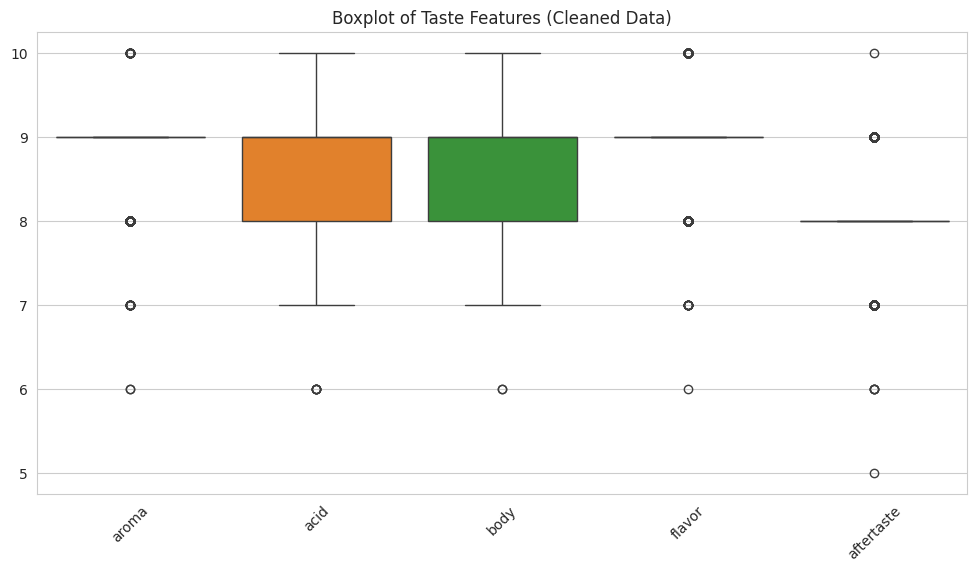


=== Cleaned Dataset Overview ===


,slug,all_text,rating,roaster,coffee_name,location,origin,roast,est_price,review_date,agtron,aroma,acid,body,flavor,aftertaste,with_milk,desc_1,desc_2,desc_3
0,https://www.coffeereview.com/review/kenya-nyer...,\n\n\n93\n\n\nLu's Coffee\nKenya Nyeri Gichat...,93,Lu's Coffee,Kenya Nyeri Gichathaini AA Top,"New Taipei City, Taiwan","Nyeri growing region, south-central Kenya",Medium-Light,NT $320/200 grams,October 2023,58/78,9.0,9.0,8.0,9.0,8.0,NaN,"Richly sweet-savory. Red currant, narcissus, t...",Produced by smallholding members of the Gikand...,"A deep-toned, sweetly savory Kenya cup with in..."
1,https://www.coffeereview.com/review/wilton-ben...,\n\n\n96\n\n\nJBC Coffee Roasters\nWilton Ben...,96,JBC Coffee Roasters,Wilton Benitez Java,"Madison, Wisconsin","Piendamó, Cauca, Colombia",Medium-Light,$25.00/8 ounces,October 2023,60/74,9.0,9.0,9.0,10.0,9.0,NaN,"Multi-layered, enigmatic. Tart citrus, myrrh, ...",Produced by Wilton Benitez entirely of the Eth...,"An impossibly complex, delightfully floral car..."
2,https://www.coffeereview.com/review/holy-melod...,\n\n\n94\n\n\nHWC Coffee Roasters\nHWC Holy M...,94,HWC Coffee Roasters,HWC Holy Melody Espresso Blend,"Taichung, Taiwan",Kenya; Ethiopia,Medium-Light,$40.00/8 ounces,September 2023,57/77,9.0,9.0,9.0,9.0,8.0,9.0,"Evaluated as espresso. Deeply sweet-savory, fr...","A blend of coffees from Kenya and Ethiopia, ro...","A complex, multi-layered espresso blend with n..."
3,https://www.coffeereview.com/review/power-drum...,\n\n\n93\n\n\nHWC Coffee Roasters\nHWC Power ...,93,HWC Coffee Roasters,HWC Power Drum Espresso Blend,"Taichung, Taiwan","Peru, Guatemala",Medium-Light,$40.00/8 ounces,September 2023,58/73,8.0,9.0,9.0,9.0,8.0,9.0,"Evaluated as espresso. Richly chocolaty, sweet...","A blend of coffees from Peru and Guatemala, ro...","A bold, chocolaty espresso blend supported by ..."
4,https://www.coffeereview.com/review/el-salvado...,\n\n\n92\n\n\nSpeedwell Coffee\nEl Salvador M...,92,Speedwell Coffee,El Salvador Monte Verde,"Plymouth, Massachusetts","Monte Verde, Santa Ana Department, central El ...",Medium-Light,$16.00/12 ounces,September 2023,60/76,8.0,9.0,8.0,9.0,8.0,NaN,"Sweetly bright, rich-toned. Baking chocolate, ...",Produced by Rene Contreras on the family farm ...,A solid El Salvador cup with a crisp chocolate...


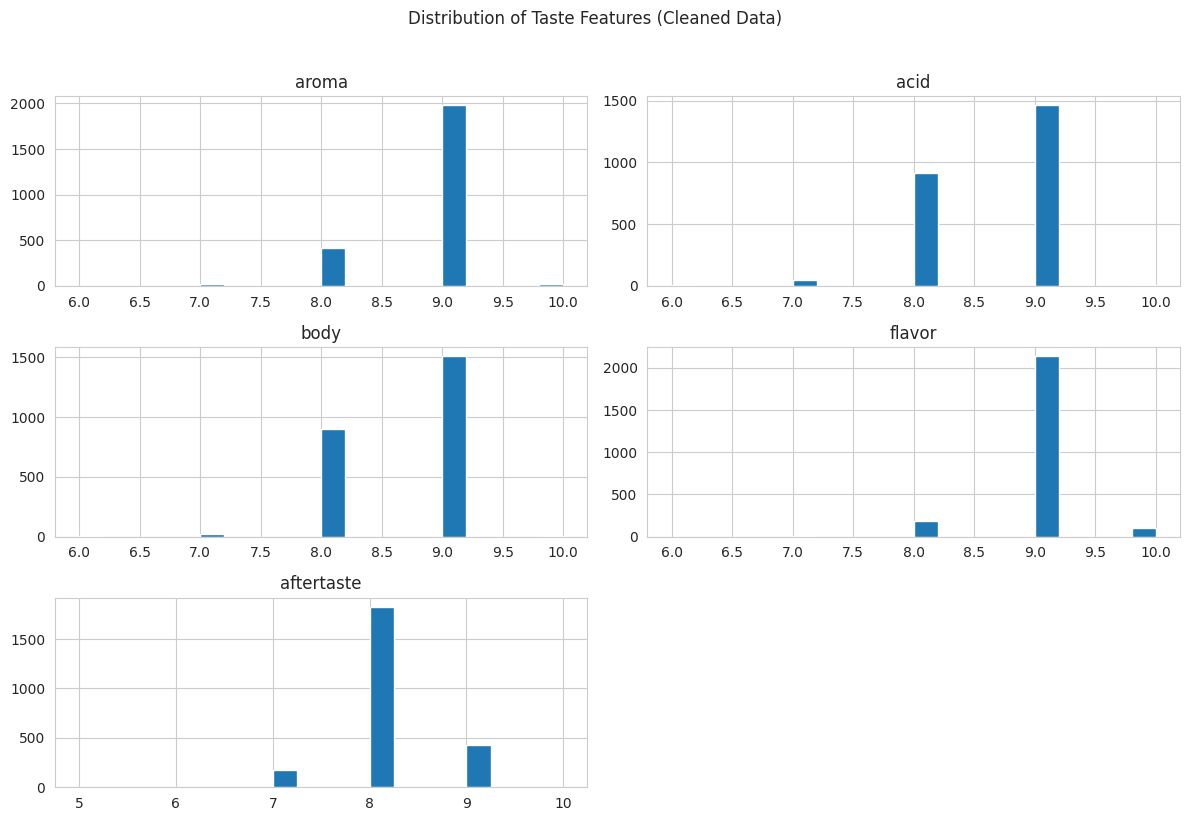

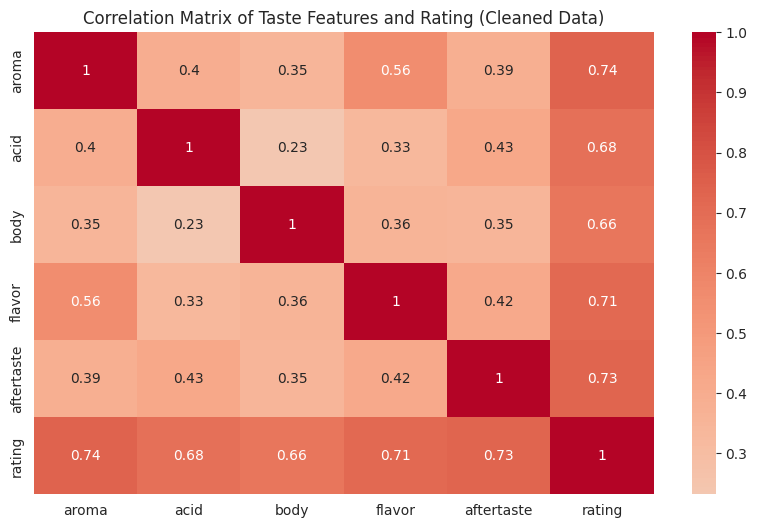

=== Normalized Data ===


,aroma,acid,body,flavor,aftertaste
0,0.75,0.75,0.50,0.75,0.6
1,0.75,0.75,0.75,1.00,0.8
2,0.75,0.75,0.75,0.75,0.6
3,0.50,0.75,0.75,0.75,0.6
4,0.50,0.75,0.50,0.75,0.6


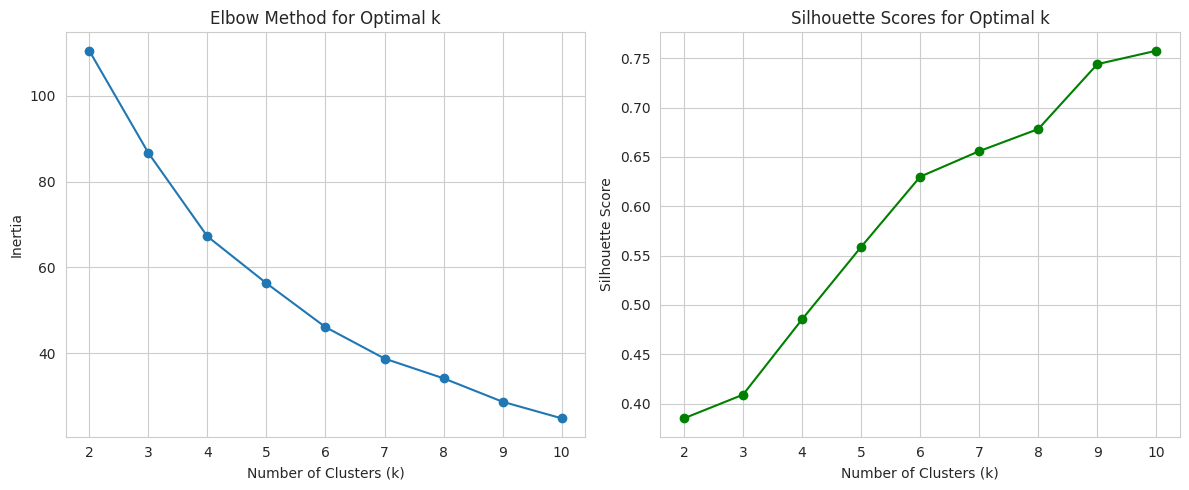

=== Cluster Centers (Taste Profiles) ===


,aroma,acid,body,flavor,aftertaste
0,0.719707,0.496005,0.665446,0.747004,0.591212
1,0.719907,0.750000,0.500000,0.744792,0.606019
2,0.746246,0.751752,0.750501,0.770521,0.672072
3,0.482558,0.489341,0.491279,0.578488,0.523256


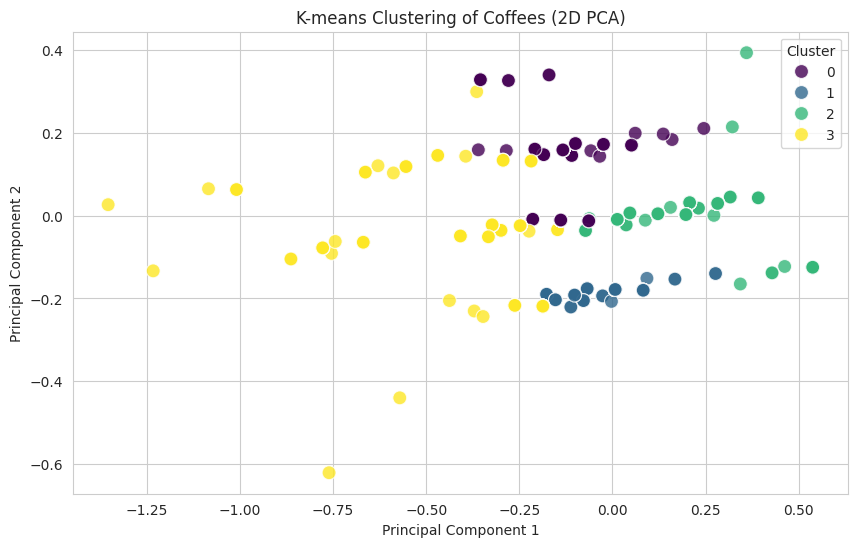

=== Model Validation ===
Silhouette Score: 0.485
Inertia: 67.233
=== User Preferences ===


,aroma,acid,body,flavor,aftertaste
0,0.9,0.5,0.8,0.7,0.8


Nearest Cluster: 0

=== Taste Profile of Nearest Cluster ===
aroma         0.719707
acid          0.496005
body          0.665446
flavor        0.747004
aftertaste    0.591212
Name: 0, dtype: float64
=== Top 5 Recommended Coffees ===


/tmp/ipykernel_1733/754292750.py:213: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  nearest_cluster_coffees['similarity'] = cosine_similarity(


,coffee_name,aroma,acid,body,flavor,aftertaste,similarity
646,Ethiopia Durato Bombe,1.00,0.5,0.75,0.75,0.8,0.997934
2404,La Providencia Guatemala Maragogype,0.75,0.5,0.75,0.75,0.8,0.996001
2022,Ecuador Eugenioides Natural Finca Perla Negra,0.75,0.5,0.75,0.75,0.8,0.996001
520,Colombia Castillo Fruit Maceration Series (Str...,0.75,0.5,0.75,0.75,0.8,0.996001
219,Blue Sunda Estate Java,0.75,0.5,0.75,0.75,0.8,0.996001


/tmp/ipykernel_1733/754292750.py:228: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


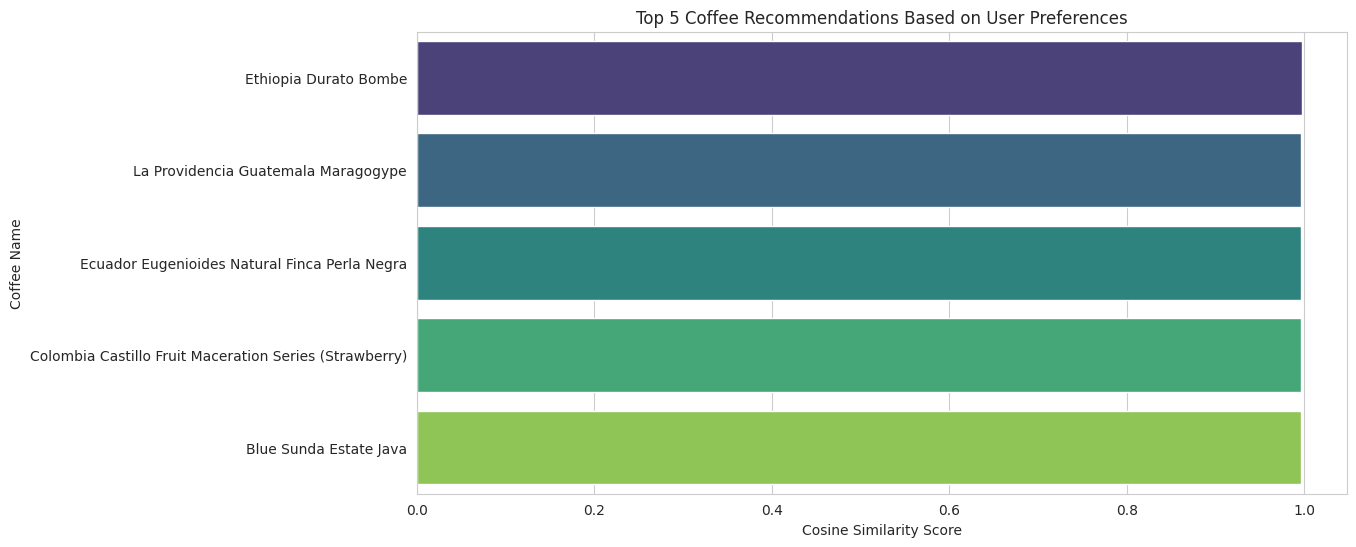

=== Top 5 Recommendations (Cosine Similarity Alone) ===


,coffee_name,aroma,acid,body,flavor,aftertaste,similarity
646,Ethiopia Durato Bombe,1.00,0.5,0.75,0.75,0.8,0.997934
790,Costa Rica Canet Musician Series Bach Raisin H...,0.75,0.5,0.75,0.75,0.8,0.996001
959,Gelena Geisha,0.75,0.5,0.75,0.75,0.8,0.996001
1439,Aged Sumatra Ulos Batak 2015,0.75,0.5,0.75,0.75,0.8,0.996001
2155,Ethiopia Guji Shakisso Natural Lot 24,0.75,0.5,0.75,0.75,0.8,0.996001


In [ ]:

# Import libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import MinMaxScaler

# Set style for visualizations
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

taste_features = ['aroma', 'acid', 'body', 'flavor', 'aftertaste']

df_raw = pd.read_csv("/content/sample_data/coffee_clean.csv")

# Display the first 5 rows
print("=== Raw Dataset Overview ===")
display(df_raw.head())

# Display dataset info
print("\n=== Raw Dataset Info ===")
print(df_raw.info())

# Display summary statistics
print("\n=== Raw Summary Statistics ===")
display(df_raw.describe())


# Missing Values
print("=== Missing Values ===")
print(df_raw.isnull().sum())

# Duplicates
print("=== Duplicate Rows ===")
print(f"Number of duplicates: {df_raw.duplicated().sum()}")

# Column Names and Types
if 'name' in df_raw.columns and 'coffee_name' not in df_raw.columns:
    df_raw = df_raw.rename(columns={'name': 'coffee_name'})

print("=== Column Data Types ===")
print(df_raw.dtypes)


# Handle missing values in taste features
for col in taste_features:
    median_val = df_raw[col].median()
    df_raw[col] = df_raw[col].fillna(median_val)

# Handle missing values in coffee_name and rating
df_raw['coffee_name'] = df_raw['coffee_name'].fillna("Unknown Coffee").str.strip()
df_raw['rating'] = df_raw['rating'].fillna(df_raw['rating'].median())

# Verify no missing values exist in target features
print("=== Missing Values after Imputation ===")
print(df_raw[taste_features + ['coffee_name', 'rating']].isnull().sum())


# Plot boxplots for taste features
plt.figure(figsize=(12, 6))
sns.boxplot(data=df_raw[taste_features])
plt.title("Boxplot of Taste Features (Cleaned Data)")
plt.xticks(rotation=45)
plt.show()


# Save the cleaned dataset
df_clean = df_raw.copy()
df_clean.to_csv("coffee_clean.csv", index=False)

# Load the cleaned dataset to verify
df = pd.read_csv("coffee_clean.csv")
print("\n=== Cleaned Dataset Overview ===")
display(df.head())


# Plot histograms for taste features
df[taste_features].hist(bins=20, figsize=(12, 8))
plt.suptitle("Distribution of Taste Features (Cleaned Data)", y=1.02)
plt.tight_layout()
plt.show()


# Plot correlation heatmap
plt.figure(figsize=(10, 6))
correlation_matrix = df[taste_features + ['rating']].corr()
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", center=0)
plt.title("Correlation Matrix of Taste Features and Rating (Cleaned Data)")
plt.show()


# Initialize the scaler
scaler = MinMaxScaler()

# Normalize the taste features
df[taste_features] = scaler.fit_transform(df[taste_features])

# Display the normalized data
print("=== Normalized Data ===")
display(df[taste_features].head())


# Calculate inertia (within-cluster sum of squares) for different values of k
inertia = []
silhouette_scores = []
k_values = range(2, 11)

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(df[taste_features])
    inertia.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(df[taste_features], kmeans.labels_))

# Plot the elbow curve
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(k_values, inertia, marker='o')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method for Optimal k')

# Plot silhouette scores
plt.subplot(1, 2, 2)
plt.plot(k_values, silhouette_scores, marker='o', color='green')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Scores for Optimal k')
plt.tight_layout()
plt.show()


# Fit K-means with the optimal k
optimal_k = 4
kameans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
kameans.fit(df[taste_features])

# Add cluster labels to the dataframe
df['cluster'] = kameans.labels_


# Get cluster centers
cluster_centers = kameans.cluster_centers_
cluster_centers_df = pd.DataFrame(cluster_centers, columns=taste_features)

# Display cluster centers
print("=== Cluster Centers (Taste Profiles) ===")
display(cluster_centers_df)


from sklearn.decomposition import PCA

# Reduce dimensions to 2D for visualization
pca = PCA(n_components=2)
df_pca = pca.fit_transform(df[taste_features])
df['pca_1'] = df_pca[:, 0]
df['pca_2'] = df_pca[:, 1]

# Plot clusters
plt.figure(figsize=(10, 6))
sns.scatterplot(
    x='pca_1',
    y='pca_2',
    hue='cluster',
    data=df,
    palette='viridis',
    s=100,
    alpha=0.8
)
plt.title('K-means Clustering of Coffees (2D PCA)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Cluster')
plt.show()


# Calculate silhouette score
silhouette_avg = silhouette_score(df[taste_features], df['cluster'])
print(f"=== Model Validation ===")
print(f"Silhouette Score: {silhouette_avg:.3f}")
print(f"Inertia: {kameans.inertia_:.3f}")


# User preferences
user_preferences = [[0.9, 0.5, 0.8, 0.7, 0.8]]
user_preferences_df = pd.DataFrame(user_preferences, columns=taste_features)

print("=== User Preferences ===")
display(user_preferences_df)


# Compute distance to each cluster center (using scaled centers)
distances = []
for center in cluster_centers:
    distance = np.linalg.norm(user_preferences[0] - center)
    distances.append(distance)

# Find the nearest cluster
nearest_cluster = np.argmin(distances)
print(f"Nearest Cluster: {nearest_cluster}")

# Print the taste profile of the nearest cluster
print("\n=== Taste Profile of Nearest Cluster ===")
print(cluster_centers_df.iloc[nearest_cluster])


# Filter coffees in the nearest cluster
nearest_cluster_coffees = df[df['cluster'] == nearest_cluster]

# Compute cosine similarity between user preferences and coffees in the nearest cluster
nearest_cluster_coffees['similarity'] = cosine_similarity(
    user_preferences,
    nearest_cluster_coffees[taste_features]
)[0]

# Sort by similarity (highest to lowest)
recommended_coffees = nearest_cluster_coffees.sort_values(by='similarity', ascending=False)

# Display the top 5 recommendations
print("=== Top 5 Recommended Coffees ===")
display(recommended_coffees[['coffee_name', 'aroma', 'acid', 'body', 'flavor', 'aftertaste', 'similarity']].head())


# Plot top 5 recommendations
plt.figure(figsize=(12, 6))
sns.barplot(
    x='similarity',
    y='coffee_name',
    data=recommended_coffees.head(5),
    palette='viridis'
)
plt.title("Top 5 Coffee Recommendations Based on User Preferences")
plt.xlabel("Cosine Similarity Score")
plt.ylabel("Coffee Name")
plt.show()


# Compute cosine similarity for all coffees
df['similarity'] = cosine_similarity(user_preferences, df[taste_features])[0]

# Sort by similarity (highest to lowest)
cosine_recommendations = df.sort_values(by='similarity', ascending=False)

# Display the top 5 recommendations
print("=== Top 5 Recommendations (Cosine Similarity Alone) ===")
display(cosine_recommendations[['coffee_name', 'aroma', 'acid', 'body', 'flavor', 'aftertaste', 'similarity']].head())

27 drinks, missing values: 0
                  name  category temperature  strength  milk_pct  foam_level  acidity  bitterness  sweetness  body  caffeine_mg
              Espresso  espresso         hot         5         0           0        4           4          1     4           63
                Doppio  espresso         hot         5         0           0        4           4          1     4          126
             Ristretto  espresso         hot         5         0           0        3           3          2     4           55
                 Lungo  espresso         hot         4         0           0        5           3          1     3           80
             Americano     black         hot         3         0           0        3           3          1     2           77
            Long Black     black         hot         4         0           0        4           4          1     3          126
           Drip Coffee     black         hot         3         0           

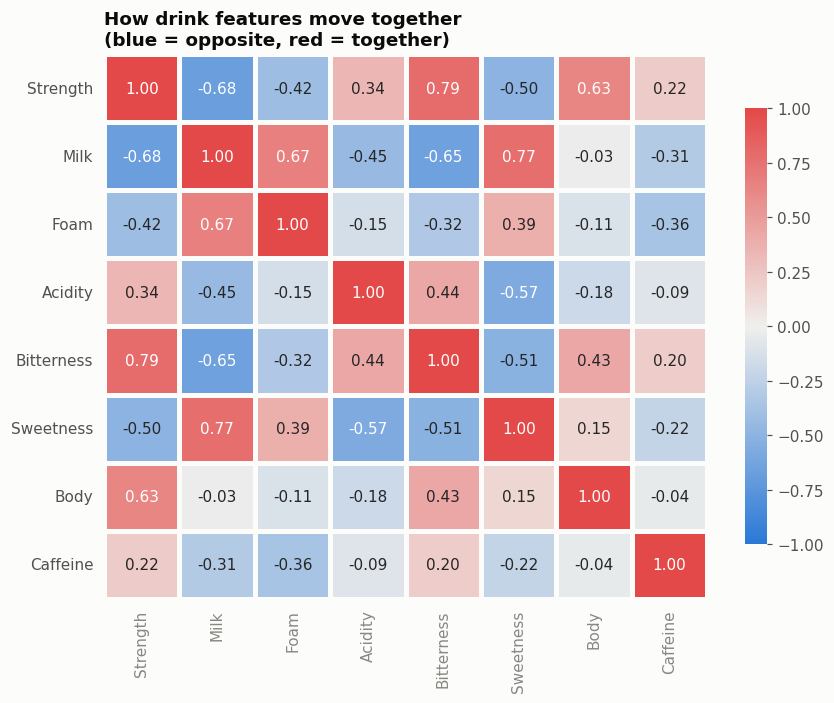

Silhouette by k: {2: np.float64(0.39), 3: np.float64(0.296), 4: np.float64(0.302), 5: np.float64(0.28), 6: np.float64(0.279), 7: np.float64(0.282), 8: np.float64(0.307)}
Best k by silhouette: 2


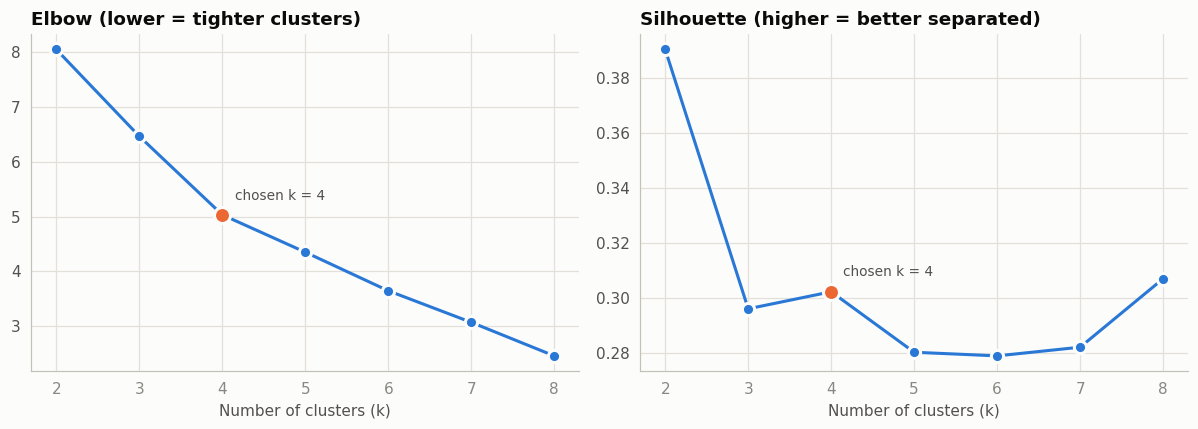


=== Cluster members ===
Cluster 0 (5): Cortado, Piccolo Latte, Flat White, Vietnamese Iced Coffee, Affogato
Cluster 1 (8): Cappuccino, Latte, Iced Latte, Vanilla Latte, Caramel Macchiato, Caffe Mocha, Iced Mocha, Spanish Latte
Cluster 2 (8): Espresso, Doppio, Ristretto, Lungo, Long Black, French Press, Turkish Coffee, Macchiato
Cluster 3 (6): Americano, Drip Coffee, Pour Over, Cold Brew, Iced Americano, Cafe au Lait

=== Cluster profiles (scaled means) ===
   strength  milk_pct  foam_level  acidity  bitterness  sweetness  body  caffeine_mg
0      0.75      0.49        0.12     0.40        0.50       0.70  0.80         0.62
1      0.31      0.77        0.40     0.28        0.25       0.81  0.53         0.44
2      0.91      0.01        0.05     0.62        0.66       0.06  0.75         0.54
3      0.54      0.08        0.03     0.42        0.38       0.12  0.33         0.66


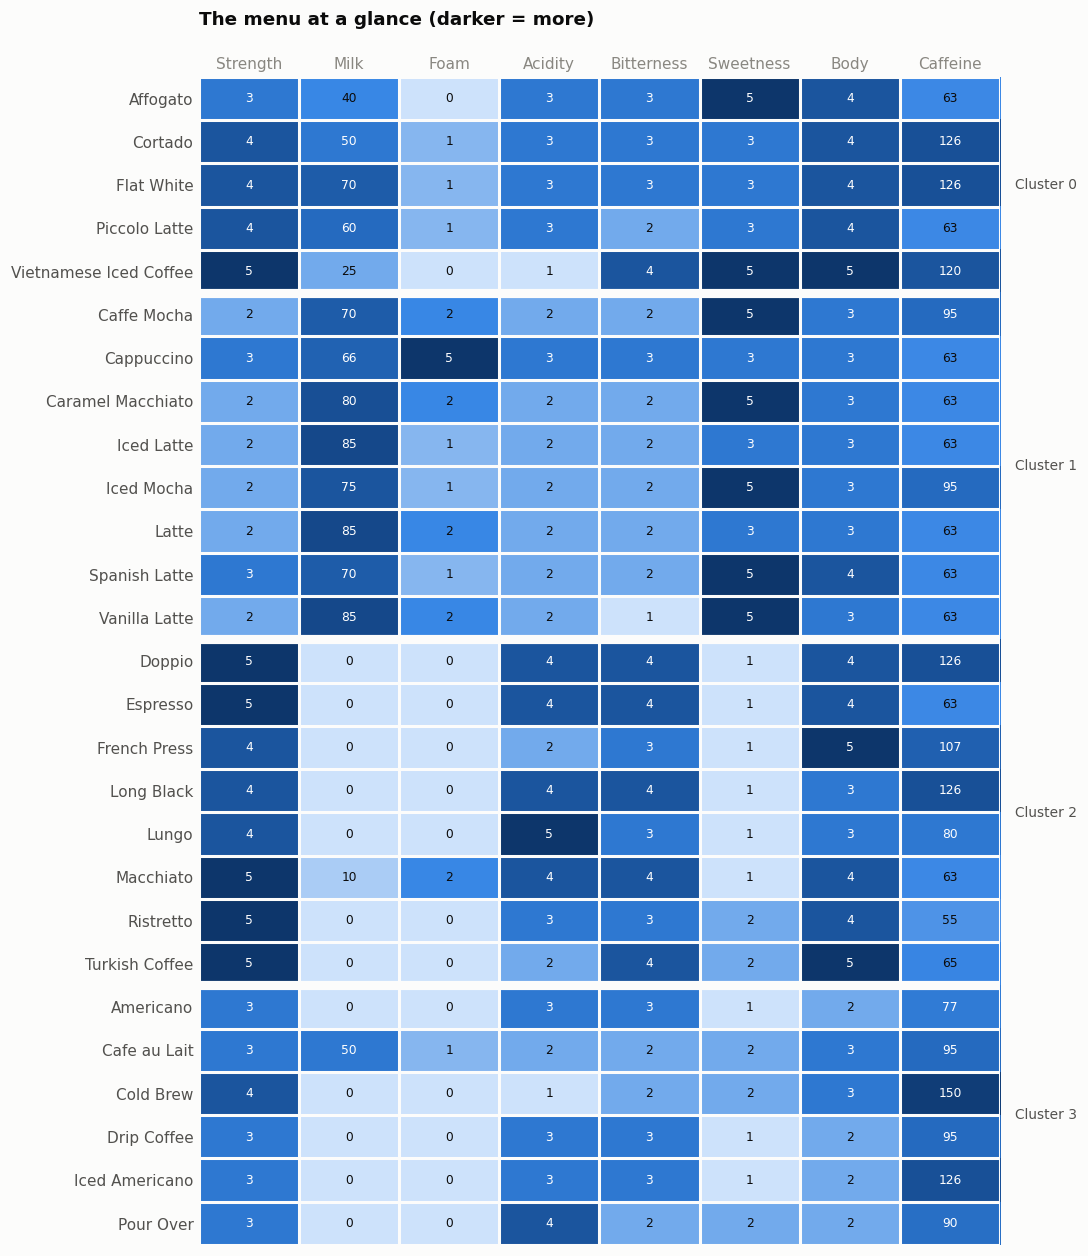

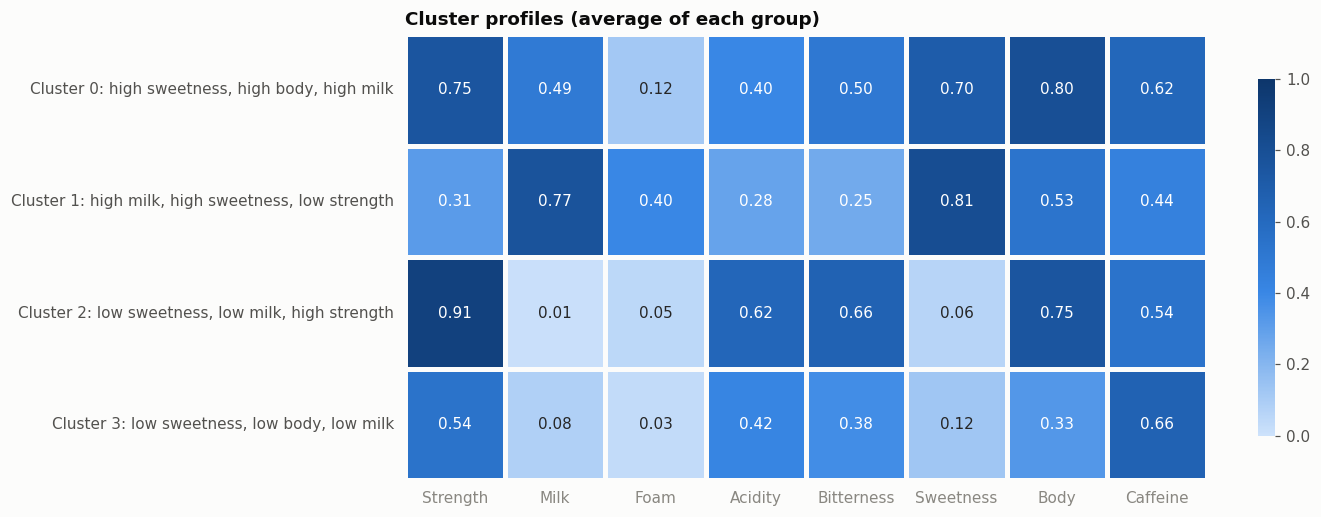

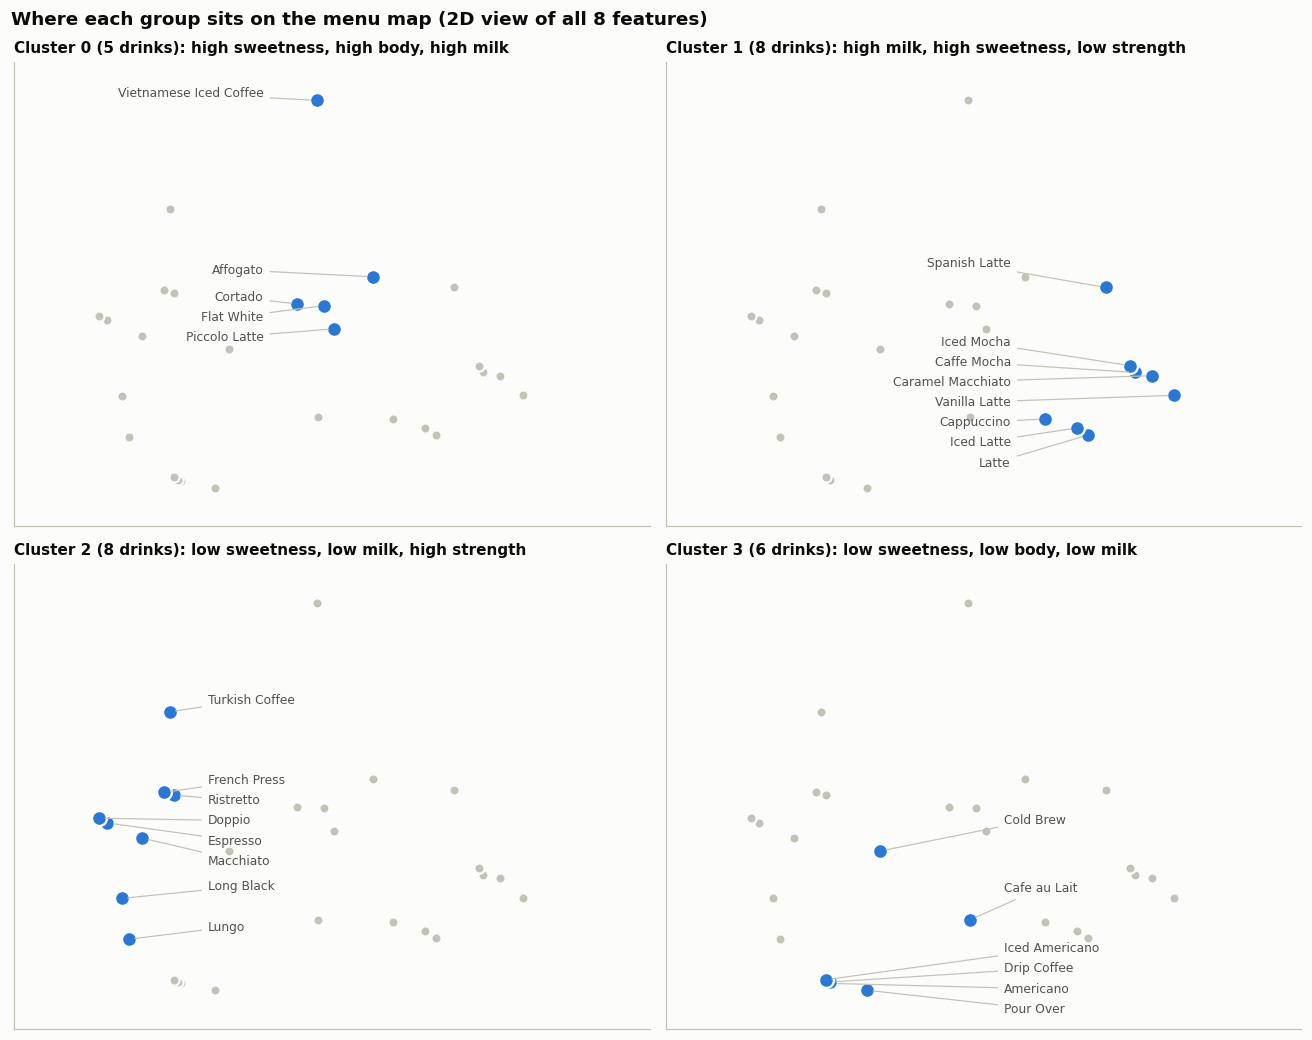


--- Sweet, milky, mild, hot ---
Caramel Macchiato        match 1.00   layered, sweet caramel, vanilla
Vanilla Latte            match 0.98   sweet vanilla, creamy, dessert-like
Caffe Mocha              match 0.95   chocolate and espresso, rich, sweet


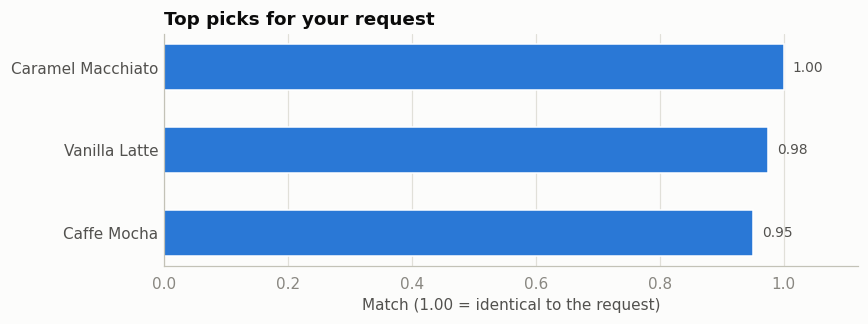

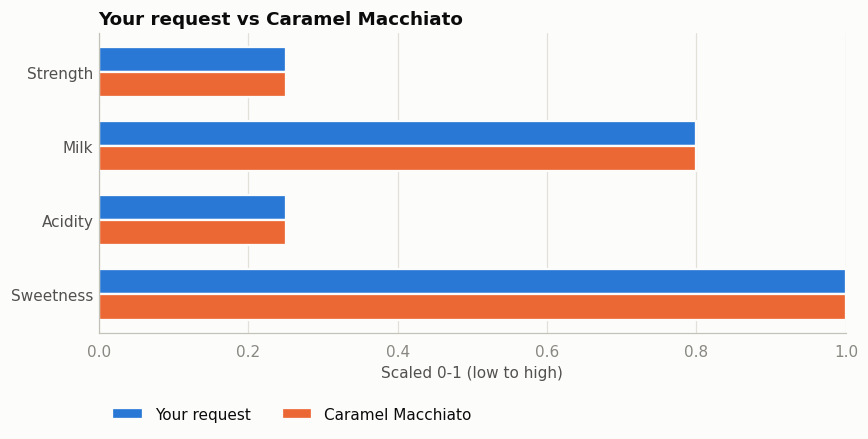


--- Strong black, no milk ---
Espresso                 match 1.00   intense, caramelised, lingering finish
Doppio                   match 1.00   intense, heavy, bittersweet
Ristretto                match 0.88   concentrated, sweeter and less bitter than espresso

--- Dairy-free, iced, bright, low caffeine ---
Iced Americano           match 0.80   refreshing, crisp, roasty

--- Similar to Flat White ---
         name  category temperature                             flavor_notes  similarity
      Cortado  espresso         hot balanced, espresso softened by warm milk       0.929
Piccolo Latte  espresso         hot              small, concentrated, creamy       0.831
 Cafe au Lait      milk         hot    drip coffee with steamed milk, mellow       0.779
Spanish Latte flavoured         hot        condensed milk, very sweet, silky       0.728


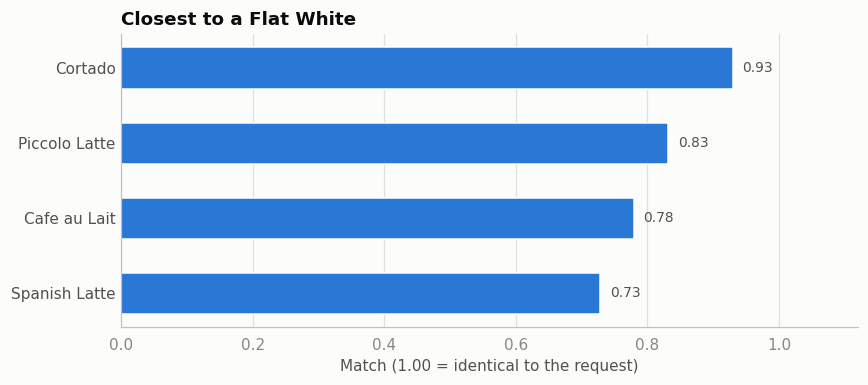


--- Similar to Iced Latte, but hot ---
             name  category temperature                          flavor_notes  similarity
            Latte      milk         hot    creamy, milky, mild coffee flavour       0.929
     Cafe au Lait      milk         hot drip coffee with steamed milk, mellow       0.810
Caramel Macchiato flavoured         hot       layered, sweet caramel, vanilla       0.809
    Vanilla Latte flavoured         hot   sweet vanilla, creamy, dessert-like       0.790

=== Sanity checks (top-3 categories should fall in expected set) ===
[PASS] sweet milky mild: ['Caramel Macchiato', 'Vanilla Latte', 'Iced Mocha']
[PASS] strong, no milk, bitter: ['Espresso', 'Doppio', 'Macchiato']
[PASS] foamy, medium milk (foam weighted x3): ['Cappuccino', 'Caffe Mocha', 'Caramel Macchiato']

Plain ranking:    ['Caffe Mocha', 'Caramel Macchiato', 'Latte', 'Vanilla Latte', 'Spanish Latte']
Within cluster:   ['Caffe Mocha', 'Caramel Macchiato', 'Latte', 'Vanilla Latte', 'Spanish Latte']


In [ ]:
# Coffee shop drink recommender (drinks-only pipeline, with visuals)
# Data: coffee_drinks.csv (27 menu drinks). coffee_clean.csv is not used here.
# Every chart is also saved as a PNG in ./plots (set SAVE_PLOTS = False to skip).
# %% 1. Imports and load
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

DRINKS_PATH = "/content/sample_data/coffee_drinks.csv"
if not os.path.exists(DRINKS_PATH):
    DRINKS_PATH = "coffee_drinks.csv"          # local fallback

drinks = pd.read_csv(DRINKS_PATH)
assert drinks["drink_id"].is_unique
assert drinks["name"].is_unique, "drink names must be unique for the 'similar to' mode"

drink_features = ["strength", "milk_pct", "foam_level", "acidity",
                  "bitterness", "sweetness", "body", "caffeine_mg"]

print(f"{len(drinks)} drinks, missing values: {int(drinks[drink_features].isnull().sum().sum())}")
print(drinks[["name", "category", "temperature"] + drink_features].to_string(index=False))


# %% 1b. Visual style
# Palette: blue = main series / "your request", orange = comparison, grey = context.
# Sequential = one blue ramp (more = darker). Diverging = blue <-> red around a neutral grey.
SAVE_PLOTS, PLOT_DIR = True, "plots"
if SAVE_PLOTS:
    os.makedirs(PLOT_DIR, exist_ok=True)

SURFACE, INK, INK2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, NEUTRAL = "#e1e0d9", "#c3c2b7", "#f0efec"
BLUE, ORANGE, RED, DIM = "#2a78d6", "#eb6834", "#e34948", "#c3c2b7"

SEQ_CMAP = LinearSegmentedColormap.from_list(
    "seq_blue", ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#184f95", "#0d366b"])
DIV_CMAP = LinearSegmentedColormap.from_list("div_blue_red", [BLUE, NEUTRAL, RED])

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "font.family": "sans-serif", "figure.dpi": 110,
})

FEATURE_LABELS = {"strength": "Strength", "milk_pct": "Milk", "foam_level": "Foam",
                  "acidity": "Acidity", "bitterness": "Bitterness",
                  "sweetness": "Sweetness", "body": "Body", "caffeine_mg": "Caffeine"}


def show(name):
    """Tidy layout, save a PNG, and display."""
    plt.tight_layout()
    if SAVE_PLOTS:
        plt.savefig(f"{PLOT_DIR}/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()


def _text_on(v):
    """Readable annotation colour on a sequential fill (v in 0-1)."""
    return "#ffffff" if v >= 0.45 else INK


# %% 2. Scaling with fixed bounds (user inputs map onto the same 0-1 scale)
drink_bounds = {
    "strength": (1, 5), "milk_pct": (0, 100), "foam_level": (0, 5),
    "acidity": (1, 5), "bitterness": (1, 5), "sweetness": (1, 5),
    "body": (1, 5), "caffeine_mg": (0, 160),
}

def scale_drink_values(frame):
    out = pd.DataFrame(index=frame.index)
    for c in frame.columns:
        lo, hi = drink_bounds[c]
        out[c] = ((frame[c].astype(float) - lo) / (hi - lo)).clip(0, 1)
    return out

drinks_scaled = scale_drink_values(drinks[drink_features])


# %% 3. EDA: which features move together?
corr = drinks_scaled.rename(columns=FEATURE_LABELS).corr()
plt.figure(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap=DIV_CMAP, center=0, vmin=-1, vmax=1,
            linewidths=2, linecolor=SURFACE, cbar_kws={"shrink": 0.8})
plt.grid(False)
plt.title("How drink features move together\n(blue = opposite, red = together)")
show("feature_correlation")


# %% 4. K-means on the drinks (small k: only 27 rows)
X = drinks_scaled.values
k_values = list(range(2, 9))
inertias, sil_scores = [], []
for k in k_values:
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X, km.labels_))

best_k = k_values[int(np.argmax(sil_scores))]
print("Silhouette by k:", {k: round(s, 3) for k, s in zip(k_values, sil_scores)})
print("Best k by silhouette:", best_k)

# k=2 scores highest but only splits "black" from "milky" (too coarse to be useful).
# k=4 scores almost the same and gives menu-friendly groups:
#   strong espresso-style / light black & brewed / milk-forward classics / sweet milky.
OPTIMAL_K = 4

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, ys, ttl in [(ax[0], inertias, "Elbow (lower = tighter clusters)"),
                   (ax[1], sil_scores, "Silhouette (higher = better separated)")]:
    a.plot(k_values, ys, marker="o", color=BLUE, lw=2, ms=8, mec=SURFACE, mew=2)
    i = k_values.index(OPTIMAL_K)
    a.scatter([OPTIMAL_K], [ys[i]], s=110, color=ORANGE, zorder=4, edgecolor=SURFACE, linewidth=2)
    a.annotate(f"chosen k = {OPTIMAL_K}", (OPTIMAL_K, ys[i]), xytext=(8, 10),
               textcoords="offset points", fontsize=9, color=INK2)
    a.set_title(ttl)
    a.set_xlabel("Number of clusters (k)")
show("elbow_silhouette")

kmeans = KMeans(n_clusters=OPTIMAL_K, random_state=42, n_init=10).fit(X)
drinks["cluster"] = kmeans.labels_
cluster_centers = kmeans.cluster_centers_        # in scaled space

print("\n=== Cluster members ===")
for c in range(OPTIMAL_K):
    members = drinks.loc[drinks["cluster"] == c, "name"].tolist()
    print(f"Cluster {c} ({len(members)}): {', '.join(members)}")

print("\n=== Cluster profiles (scaled means) ===")
print(pd.DataFrame(cluster_centers, columns=drink_features).round(2).to_string())


# %% 4b. Cluster and menu visuals
def cluster_label(c):
    """Auto-name a cluster by the three features that set it apart from the menu average."""
    dev = pd.Series(cluster_centers[c], index=drink_features) - drinks_scaled.mean()
    top = dev.abs().sort_values(ascending=False).index[:3]
    return ", ".join(f"{'high' if dev[f] > 0 else 'low'} {FEATURE_LABELS[f].lower()}" for f in top)


def plot_menu_heatmap():
    """Every drink x every feature; darker = more. Numbers are the raw values."""
    order = drinks.sort_values(["cluster", "name"]).index
    data, raw = drinks_scaled.loc[order], drinks.loc[order, drink_features]
    n, m = len(order), len(drink_features)
    fig, ax = plt.subplots(figsize=(10, 0.36 * n + 1.8))
    ax.imshow(data.values, cmap=SEQ_CMAP, vmin=0, vmax=1, aspect="auto")
    ax.set_xticks(range(m))
    ax.set_xticklabels([FEATURE_LABELS[f] for f in drink_features])
    ax.xaxis.tick_top()
    ax.set_yticks(range(n))
    ax.set_yticklabels(drinks.loc[order, "name"])
    ax.grid(False)
    ax.set_xticks(np.arange(-.5, m), minor=True)
    ax.set_yticks(np.arange(-.5, n), minor=True)
    ax.grid(which="minor", color=SURFACE, linewidth=2)
    ax.tick_params(which="both", length=0)
    for r in range(n):
        for k in range(m):
            ax.text(k, r, f"{raw.iloc[r, k]:g}", ha="center", va="center",
                    fontsize=8, color=_text_on(data.iloc[r, k]))
    cl = drinks.loc[order, "cluster"].values
    for r in range(1, n):
        if cl[r] != cl[r - 1]:
            ax.axhline(r - 0.5, color=SURFACE, linewidth=6)
    for c in np.unique(cl):
        rows = np.where(cl == c)[0]
        ax.text(m - 0.35, rows.mean(), f"Cluster {c}", va="center", fontsize=9,
                color=INK2, clip_on=False)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.set_title("The menu at a glance (darker = more)", pad=34)
    show("menu_heatmap")


def plot_cluster_profiles():
    """What each cluster is like, on the 0-1 scale."""
    centers = pd.DataFrame(cluster_centers, columns=[FEATURE_LABELS[f] for f in drink_features])
    centers.index = [f"Cluster {c}: {cluster_label(c)}" for c in range(len(centers))]
    plt.figure(figsize=(13, 0.8 * len(centers) + 1.6))
    sns.heatmap(centers, annot=True, fmt=".2f", cmap=SEQ_CMAP, vmin=0, vmax=1,
                linewidths=2, linecolor=SURFACE, cbar_kws={"shrink": 0.8})
    plt.grid(False)
    plt.xticks(rotation=0)
    plt.title("Cluster profiles (average of each group)")
    show("cluster_profiles")


def _spread_labels(ax, pts, names, xr, yr, ylim, x_centre):
    """Put the labels in one aligned column beside the group, spaced so near-identical
    drinks (Espresso/Doppio, Americano/Drip Coffee...) stay readable and lines don't cross."""
    order = np.argsort(-pts[:, 1])
    ys = pts[order, 1].astype(float)
    gap = 0.052 * yr
    for j in range(1, len(ys)):
        ys[j] = min(ys[j], ys[j - 1] - gap)
    ys += pts[order, 1].mean() - ys.mean()          # centre the block on its points
    lo, hi = ylim[0] + gap, ylim[1] - gap           # keep every label inside the plot
    if ys.max() > hi:
        ys -= ys.max() - hi
    if ys.min() < lo:
        ys += lo - ys.min()
    on_right = pts[:, 0].mean() <= x_centre         # group on the left -> labels to its right
    lx = pts[:, 0].max() + 0.08 * xr if on_right else pts[:, 0].min() - 0.08 * xr
    for (px, py), ly, name in zip(pts[order], ys, np.array(names)[order]):
        ax.annotate(name, (px, py), xytext=(lx, ly), fontsize=8, color=INK2,
                    ha="left" if on_right else "right", va="center",
                    arrowprops=dict(arrowstyle="-", color=AXIS, linewidth=0.8,
                                    shrinkA=2, shrinkB=4))


def plot_cluster_panels():
    """One small map per cluster: its drinks in blue and labelled, the rest in grey."""
    coords = PCA(n_components=2, random_state=42).fit_transform(X)
    xr, yr = np.ptp(coords[:, 0]), np.ptp(coords[:, 1])
    n, cols = OPTIMAL_K, 2
    rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(12, 4.8 * rows), sharex=True, sharey=True)
    flat = np.ravel(axes)
    for c, ax in zip(range(n), flat):
        mine = (drinks["cluster"] == c).values
        ax.scatter(coords[~mine, 0], coords[~mine, 1], s=45, color=DIM,
                   edgecolor=SURFACE, linewidth=1.5, zorder=2)
        ax.scatter(coords[mine, 0], coords[mine, 1], s=95, color=BLUE,
                   edgecolor=SURFACE, linewidth=1.5, zorder=3)
        ylim = (coords[:, 1].min() - 0.1 * yr, coords[:, 1].max() + 0.1 * yr)
        ax.set_xlim(coords[:, 0].min() - 0.2 * xr, coords[:, 0].max() + 0.3 * xr)
        ax.set_ylim(*ylim)
        _spread_labels(ax, coords[mine], drinks.loc[mine, "name"].tolist(), xr, yr,
                       ylim, coords[:, 0].mean())
        ax.set_title(f"Cluster {c} ({mine.sum()} drinks): {cluster_label(c)}", fontsize=10)
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for ax in flat[n:]:
        ax.axis("off")
    fig.suptitle("Where each group sits on the menu map (2D view of all 8 features)",
                 x=0.01, ha="left", fontsize=12, fontweight="bold")
    show("cluster_panels")


plot_menu_heatmap()
plot_cluster_profiles()
plot_cluster_panels()


# %% 5. Core recommender: preferences -> ranked drinks
def _apply_filters(frame, temperature=None, max_caffeine=None, no_milk=False,
                   categories=None):
    mask = pd.Series(True, index=frame.index)
    if temperature:
        # 'hot-cold' drinks (e.g. Affogato) match either request
        mask &= frame["temperature"].isin([temperature, "hot-cold"])
    if max_caffeine is not None:
        mask &= frame["caffeine_mg"] <= max_caffeine
    if no_milk:
        mask &= frame["milk_pct"] == 0
    if categories:
        mask &= frame["category"].isin(categories)
    return mask


def _weighted_distance(scaled_frame, target, weights, cols):
    w = pd.Series({f: (weights or {}).get(f, 1.0) for f in cols})
    diff = scaled_frame[cols] - target[cols]
    return np.sqrt((w * diff ** 2).sum(axis=1) / w.sum())   # 0 = identical


def recommend_drinks(prefs, weights=None, top_n=5, within_cluster=False,
                     **filters):
    """
    prefs: raw drink scales, e.g. {'strength': 3, 'milk_pct': 70, 'sweetness': 4}
           (strength/acidity/bitterness/sweetness/body 1-5, foam 0-5,
            milk_pct 0-100, caffeine_mg 0-160). Omitted features are ignored.
    weights: optional {'sweetness': 2.0} to make a feature matter more.
    within_cluster: restrict to the cluster whose centre is nearest the prefs.
    filters: temperature='hot'|'iced', max_caffeine=int, no_milk=bool, categories=[...]
    """
    unknown = set(prefs) - set(drink_features)
    if unknown:
        raise ValueError(f"Unknown preference(s): {sorted(unknown)}")
    given = [f for f in drink_features if f in prefs]
    if not given:
        raise ValueError("Give at least one drink preference.")

    user = scale_drink_values(pd.DataFrame([{f: prefs[f] for f in given}])).iloc[0]

    out = drinks.copy()
    out["distance"] = _weighted_distance(drinks_scaled, user, weights, given)
    out["similarity"] = 1 - out["distance"]

    mask = _apply_filters(out, **filters)
    if within_cluster:
        idx = [drink_features.index(f) for f in given]
        centers = pd.DataFrame(cluster_centers[:, idx], columns=given)
        w = np.array([(weights or {}).get(f, 1.0) for f in given])
        d = np.sqrt((w * (centers - user[given]) ** 2).sum(axis=1) / w.sum())
        nearest = int(d.values.argmin())
        in_cluster = mask & (out["cluster"] == nearest)
        if in_cluster.sum() >= top_n:      # otherwise fall back to the full menu
            mask = in_cluster

    out = out[mask].sort_values("similarity", ascending=False)
    return out[["name", "category", "temperature"] + given + ["similarity"]].head(top_n)


# %% 6. "Similar to X" mode
def similar_drinks(drink_name, weights=None, top_n=5, **filters):
    """Drinks closest to an existing menu item (e.g. 'I liked my Flat White')."""
    match = drinks.index[drinks["name"].str.lower() == drink_name.lower()]
    if len(match) == 0:
        close = drinks["name"][drinks["name"].str.contains(drink_name, case=False)].tolist()
        raise ValueError(f"'{drink_name}' not on the menu. Did you mean: {close or drinks['name'].tolist()}")
    i = match[0]

    out = drinks.copy()
    out["distance"] = _weighted_distance(drinks_scaled, drinks_scaled.loc[i],
                                         weights, drink_features)
    out["similarity"] = 1 - out["distance"]

    mask = _apply_filters(out, **filters) & (out.index != i)   # exclude itself
    out = out[mask].sort_values("similarity", ascending=False)
    return out[["name", "category", "temperature", "flavor_notes", "similarity"]].head(top_n)


# %% 7. Recommendation visuals + full pipeline
def plot_recommendations(picks, title, filename="recommendations"):
    """Ranked bars: best match on top."""
    p = picks.iloc[::-1]
    fig, ax = plt.subplots(figsize=(8, 0.55 * len(p) + 1.4))
    ax.barh(p["name"], p["similarity"], height=0.55, color=BLUE)
    for y, v in enumerate(p["similarity"]):
        ax.text(v + 0.015, y, f"{v:.2f}", va="center", fontsize=9, color=INK2)
    ax.set_xlim(0, 1.12)
    ax.set_xlabel("Match (1.00 = identical to the request)")
    ax.set_title(title)
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", length=0)
    show(filename)


def plot_request_vs_drink(prefs, drink_name, filename="request_vs_drink"):
    """Why this drink? The request next to the drink, feature by feature."""
    feats = [f for f in drink_features if f in prefs]
    req = scale_drink_values(pd.DataFrame([{f: prefs[f] for f in feats}])).iloc[0]
    row = drinks_scaled.loc[drinks["name"] == drink_name, feats].iloc[0]
    y, h = np.arange(len(feats)), 0.34
    fig, ax = plt.subplots(figsize=(8, 0.6 * len(feats) + 1.8))
    ax.barh(y - h / 2, req.values, height=h, color=BLUE, edgecolor=SURFACE,
            linewidth=1.5, label="Your request")
    ax.barh(y + h / 2, row.values, height=h, color=ORANGE, edgecolor=SURFACE,
            linewidth=1.5, label=drink_name)
    ax.set_yticks(y)
    ax.set_yticklabels([FEATURE_LABELS[f] for f in feats])
    ax.invert_yaxis()
    ax.set_xlim(0, 1)
    ax.set_xlabel("Scaled 0-1 (low to high)")
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", length=0)
    ax.legend(frameon=False, ncol=2, loc="upper left", bbox_to_anchor=(0, -0.2))
    ax.set_title(f"Your request vs {drink_name}")
    show(filename)


def recommend(prefs, top_n=3, plot=True, **kwargs):
    picks = recommend_drinks(prefs, top_n=top_n, **kwargs)
    if picks.empty:
        print("No drinks match those filters.")
        return picks
    notes = drinks.set_index("name")["flavor_notes"]
    for _, r in picks.iterrows():
        print(f"{r['name']:<24} match {r['similarity']:.2f}   {notes[r['name']]}")
    if plot:
        plot_recommendations(picks, "Top picks for your request")
        plot_request_vs_drink(prefs, picks.iloc[0]["name"])
    return picks


# %% 8. Try it
print("\n--- Sweet, milky, mild, hot ---")
recommend({"strength": 2, "milk_pct": 80, "sweetness": 5, "acidity": 2},
          temperature="hot")

print("\n--- Strong black, no milk ---")
recommend({"strength": 5, "milk_pct": 0, "sweetness": 1, "body": 4}, no_milk=True,
          plot=False)

print("\n--- Dairy-free, iced, bright, low caffeine ---")
recommend({"strength": 3, "acidity": 4, "sweetness": 2},
          temperature="iced", no_milk=True, max_caffeine=130, plot=False)

print("\n--- Similar to Flat White ---")
sim = similar_drinks("Flat White", top_n=4)
print(sim.round(3).to_string(index=False))
plot_recommendations(sim, "Closest to a Flat White", "similar_flat_white")

print("\n--- Similar to Iced Latte, but hot ---")
print(similar_drinks("Iced Latte", temperature="hot", top_n=4).round(3).to_string(index=False))


# %% 9. Sanity checks (no ground truth exists, so test expected behaviour)
checks = [
    ("sweet milky mild",
     {"strength": 2, "milk_pct": 80, "sweetness": 5},
     {"flavoured", "milk"}),
    ("strong, no milk, bitter",
     {"strength": 5, "milk_pct": 0, "bitterness": 4, "sweetness": 1},
     {"espresso", "black"}),
    ("foamy, medium milk (foam weighted x3)",
     {"strength": 3, "milk_pct": 66, "foam_level": 5},
     {"milk", "flavoured"},
     {"foam_level": 3}),
]
print("\n=== Sanity checks (top-3 categories should fall in expected set) ===")
for label, prefs, expected, *opt in checks:
    top = recommend_drinks(prefs, weights=opt[0] if opt else None, top_n=3)
    ok = set(top["category"]) <= expected
    print(f"[{'PASS' if ok else 'CHECK'}] {label}: {top['name'].tolist()}")

# Does restricting to the nearest cluster change the answer vs plain ranking?
test = {"strength": 3, "milk_pct": 70, "foam_level": 3, "acidity": 2,
        "sweetness": 4, "caffeine_mg": 100}
plain = recommend_drinks(test, top_n=5)["name"].tolist()
clustered = recommend_drinks(test, top_n=5, within_cluster=True)["name"].tolist()
print("\nPlain ranking:   ", plain)
print("Within cluster:  ", clustered)
print("Overlap:", len(set(plain) & set(clustered)), "/ 5")

### 1. Imports and Data Loading

In [ ]:
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

DRINKS_PATH = "/content/sample_data/coffee_drinks.csv"
if not os.path.exists(DRINKS_PATH):
    DRINKS_PATH = "coffee_drinks.csv"

# Automatically generate the coffee_drinks dataset if it's not found
if not os.path.exists(DRINKS_PATH):
    print("coffee_drinks.csv not found. Generating sample menu dataset...")
    data = [
        [1, "Espresso", "espresso", "hot", 5, 0, 0, 4, 4, 1, 4, 63, "intense, bold, rich, bitter"],
        [2, "Doppio", "espresso", "hot", 5, 0, 0, 4, 4, 1, 4, 126, "extra strong, intense, concentrated"],
        [3, "Ristretto", "espresso", "hot", 5, 0, 0, 3, 3, 2, 4, 55, "sweet, concentrated espresso"],
        [4, "Lungo", "espresso", "hot", 4, 0, 0, 5, 3, 1, 3, 80, "stretched, slightly bitter espresso"],
        [5, "Americano", "black", "hot", 3, 0, 0, 3, 3, 1, 2, 77, "diluted, balanced espresso"],
        [6, "Long Black", "black", "hot", 4, 0, 0, 4, 4, 1, 3, 126, "strong, aromatic black coffee"],
        [7, "Drip Coffee", "black", "hot", 3, 0, 0, 3, 3, 1, 2, 95, "classic filter coffee, smooth"],
        [8, "Pour Over", "black", "hot", 3, 0, 0, 4, 2, 2, 2, 90, "clean, complex, bright flavor"],
        [9, "French Press", "black", "hot", 4, 0, 0, 2, 3, 1, 5, 107, "full-bodied, robust, earthy"],
        [10, "Cold Brew", "black", "iced", 4, 0, 0, 1, 2, 2, 3, 150, "smooth, low-acid, refreshing"],
        [11, "Iced Americano", "black", "iced", 3, 0, 0, 3, 3, 1, 2, 126, "chilled, crisp, dilute espresso"],
        [12, "Turkish Coffee", "black", "hot", 5, 0, 0, 2, 4, 2, 5, 65, "unfiltered, thick, spiced notes"],
        [13, "Macchiato", "espresso", "hot", 5, 10, 2, 4, 4, 1, 4, 63, "espresso with a dash of foam"],
        [14, "Cortado", "espresso", "hot", 4, 50, 1, 3, 3, 3, 4, 126, "perfectly balanced milk & espresso"],
        [15, "Piccolo Latte", "espresso", "hot", 4, 60, 1, 3, 2, 3, 4, 63, "small, strong, milky espresso"],
        [16, "Flat White", "milk", "hot", 4, 70, 1, 3, 3, 3, 4, 126, "velvety, smooth, milk-forward"],
        [17, "Cappuccino", "milk", "hot", 3, 66, 5, 3, 3, 3, 3, 63, "airy, frothy, classic espresso drink"],
        [18, "Cafe au Lait", "milk", "hot", 3, 50, 1, 2, 2, 2, 3, 95, "brewed coffee with warm milk"],
        [19, "Latte", "milk", "hot", 2, 85, 2, 2, 2, 3, 3, 63, "creamy, mild, classic espresso & milk"],
        [20, "Iced Latte", "milk", "iced", 2, 85, 1, 2, 2, 3, 3, 63, "chilled, creamy, refreshingly milky"],
        [21, "Vanilla Latte", "flavoured", "hot", 2, 85, 2, 2, 1, 5, 3, 63, "sweet, fragrant, vanilla infusion"],
        [22, "Caramel Macchiato", "flavoured", "hot", 2, 80, 2, 2, 2, 5, 3, 63, "buttery caramel, sweet, layered"],
        [23, "Caffe Mocha", "flavoured", "hot", 2, 70, 2, 2, 2, 5, 3, 95, "chocolate, rich, sweet, comforting"],
        [24, "Iced Mocha", "flavoured", "iced", 2, 75, 1, 2, 2, 5, 3, 95, "chilled, sweet chocolate & espresso"],
        [25, "Spanish Latte", "flavoured", "hot", 3, 70, 1, 2, 2, 5, 4, 63, "sweet condensed milk, rich cream"],
        [26, "Vietnamese Iced Coffee", "flavoured", "iced", 5, 25, 0, 1, 4, 5, 5, 120, "very strong, sweet, robust, dark"],
        [27, "Affogato", "dessert", "hot-cold", 3, 40, 0, 3, 3, 5, 4, 63, "espresso poured over vanilla ice cream"]
    ]
    cols = ["drink_id", "name", "category", "temperature", "strength", "milk_pct",
            "foam_level", "acidity", "bitterness", "sweetness", "body", "caffeine_mg", "flavor_notes"]
    pd.DataFrame(data, columns=cols).to_csv(DRINKS_PATH, index=False)

drinks = pd.read_csv(DRINKS_PATH)
assert drinks["drink_id"].is_unique
assert drinks["name"].is_unique, "drink names must be unique for the 'similar to' mode"

drink_features = ["strength", "milk_pct", "foam_level", "acidity",
                  "bitterness", "sweetness", "body", "caffeine_mg"]

print(f"{len(drinks)} drinks, missing values: {int(drinks[drink_features].isnull().sum().sum())}")
display(drinks[["name", "category", "temperature"] + drink_features].head())

27 drinks, missing values: 0


,name,category,temperature,strength,milk_pct,foam_level,acidity,bitterness,sweetness,body,caffeine_mg
0,Espresso,espresso,hot,5,0,0,4,4,1,4,63
1,Doppio,espresso,hot,5,0,0,4,4,1,4,126
2,Ristretto,espresso,hot,5,0,0,3,3,2,4,55
3,Lungo,espresso,hot,4,0,0,5,3,1,3,80
4,Americano,black,hot,3,0,0,3,3,1,2,77


### 2. Visualization Style Settings

In [ ]:
SAVE_PLOTS, PLOT_DIR = True, "plots"
if SAVE_PLOTS:
    os.makedirs(PLOT_DIR, exist_ok=True)

SURFACE, INK, INK2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, NEUTRAL = "#e1e0d9", "#c3c2b7", "#f0efec"
BLUE, ORANGE, RED, DIM = "#2a78d6", "#eb6834", "#e34948", "#c3c2b7"

SEQ_CMAP = LinearSegmentedColormap.from_list(
    "seq_blue", ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#184f95", "#0d366b"])
DIV_CMAP = LinearSegmentedColormap.from_list("div_blue_red", [BLUE, NEUTRAL, RED])

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "font.family": "sans-serif", "figure.dpi": 110,
})

FEATURE_LABELS = {"strength": "Strength", "milk_pct": "Milk", "foam_level": "Foam",
                  "acidity": "Acidity", "bitterness": "Bitterness",
                  "sweetness": "Sweetness", "body": "Body", "caffeine_mg": "Caffeine"}

def show(name):
    """Tidy layout, save a PNG, and display."""
    plt.tight_layout()
    if SAVE_PLOTS:
        plt.savefig(f"{PLOT_DIR}/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

def _text_on(v):
    """Readable annotation colour on a sequential fill (v in 0-1)."""
    return "#ffffff" if v >= 0.45 else INK

### 3. Feature Scaling

In [ ]:
drink_bounds = {
    "strength": (1, 5), "milk_pct": (0, 100), "foam_level": (0, 5),
    "acidity": (1, 5), "bitterness": (1, 5), "sweetness": (1, 5),
    "body": (1, 5), "caffeine_mg": (0, 160),
}

def scale_drink_values(frame):
    out = pd.DataFrame(index=frame.index)
    for c in frame.columns:
        lo, hi = drink_bounds[c]
        out[c] = ((frame[c].astype(float) - lo) / (hi - lo)).clip(0, 1)
    return out

drinks_scaled = scale_drink_values(drinks[drink_features])

### 4. Exploratory Data Analysis

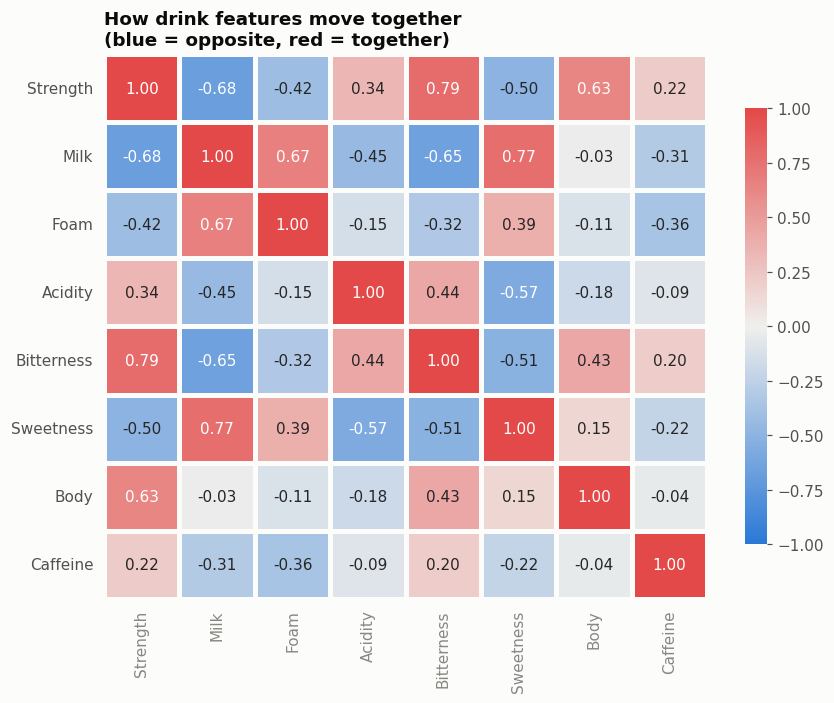

In [ ]:
corr = drinks_scaled.rename(columns=FEATURE_LABELS).corr()
plt.figure(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap=DIV_CMAP, center=0, vmin=-1, vmax=1,
            linewidths=2, linecolor=SURFACE, cbar_kws={"shrink": 0.8})
plt.grid(False)
plt.title("How drink features move together\n(blue = opposite, red = together)")
show("feature_correlation")

### 5. K-Means Clustering & Evaluation

Silhouette by k: {2: np.float64(0.39), 3: np.float64(0.296), 4: np.float64(0.302), 5: np.float64(0.28), 6: np.float64(0.279), 7: np.float64(0.282), 8: np.float64(0.307)}
Best k by silhouette: 2


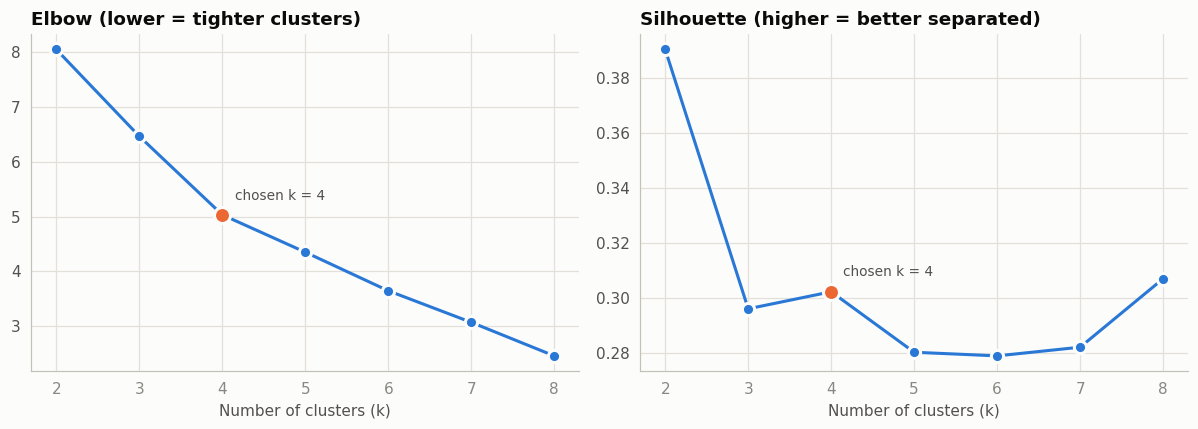


=== Cluster members ===
Cluster 0 (5): Cortado, Piccolo Latte, Flat White, Vietnamese Iced Coffee, Affogato
Cluster 1 (8): Cappuccino, Latte, Iced Latte, Vanilla Latte, Caramel Macchiato, Caffe Mocha, Iced Mocha, Spanish Latte
Cluster 2 (8): Espresso, Doppio, Ristretto, Lungo, Long Black, French Press, Turkish Coffee, Macchiato
Cluster 3 (6): Americano, Drip Coffee, Pour Over, Cold Brew, Iced Americano, Cafe au Lait


In [ ]:
X = drinks_scaled.values
k_values = list(range(2, 9))
inertias, sil_scores = [], []
for k in k_values:
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X, km.labels_))

best_k = k_values[int(np.argmax(sil_scores))]
print("Silhouette by k:", {k: round(s, 3) for k, s in zip(k_values, sil_scores)})
print("Best k by silhouette:", best_k)

OPTIMAL_K = 4

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, ys, ttl in [(ax[0], inertias, "Elbow (lower = tighter clusters)"),
                   (ax[1], sil_scores, "Silhouette (higher = better separated)")]:
    a.plot(k_values, ys, marker="o", color=BLUE, lw=2, ms=8, mec=SURFACE, mew=2)
    i = k_values.index(OPTIMAL_K)
    a.scatter([OPTIMAL_K], [ys[i]], s=110, color=ORANGE, zorder=4, edgecolor=SURFACE, linewidth=2)
    a.annotate(f"chosen k = {OPTIMAL_K}", (OPTIMAL_K, ys[i]), xytext=(8, 10),
               textcoords="offset points", fontsize=9, color=INK2)
    a.set_title(ttl)
    a.set_xlabel("Number of clusters (k)")
show("elbow_silhouette")

kmeans = KMeans(n_clusters=OPTIMAL_K, random_state=42, n_init=10).fit(X)
drinks["cluster"] = kmeans.labels_
cluster_centers = kmeans.cluster_centers_

print("\n=== Cluster members ===")
for c in range(OPTIMAL_K):
    members = drinks.loc[drinks["cluster"] == c, "name"].tolist()
    print(f"Cluster {c} ({len(members)}): {', '.join(members)}")

### 6. Cluster Visualizations & Menu Map

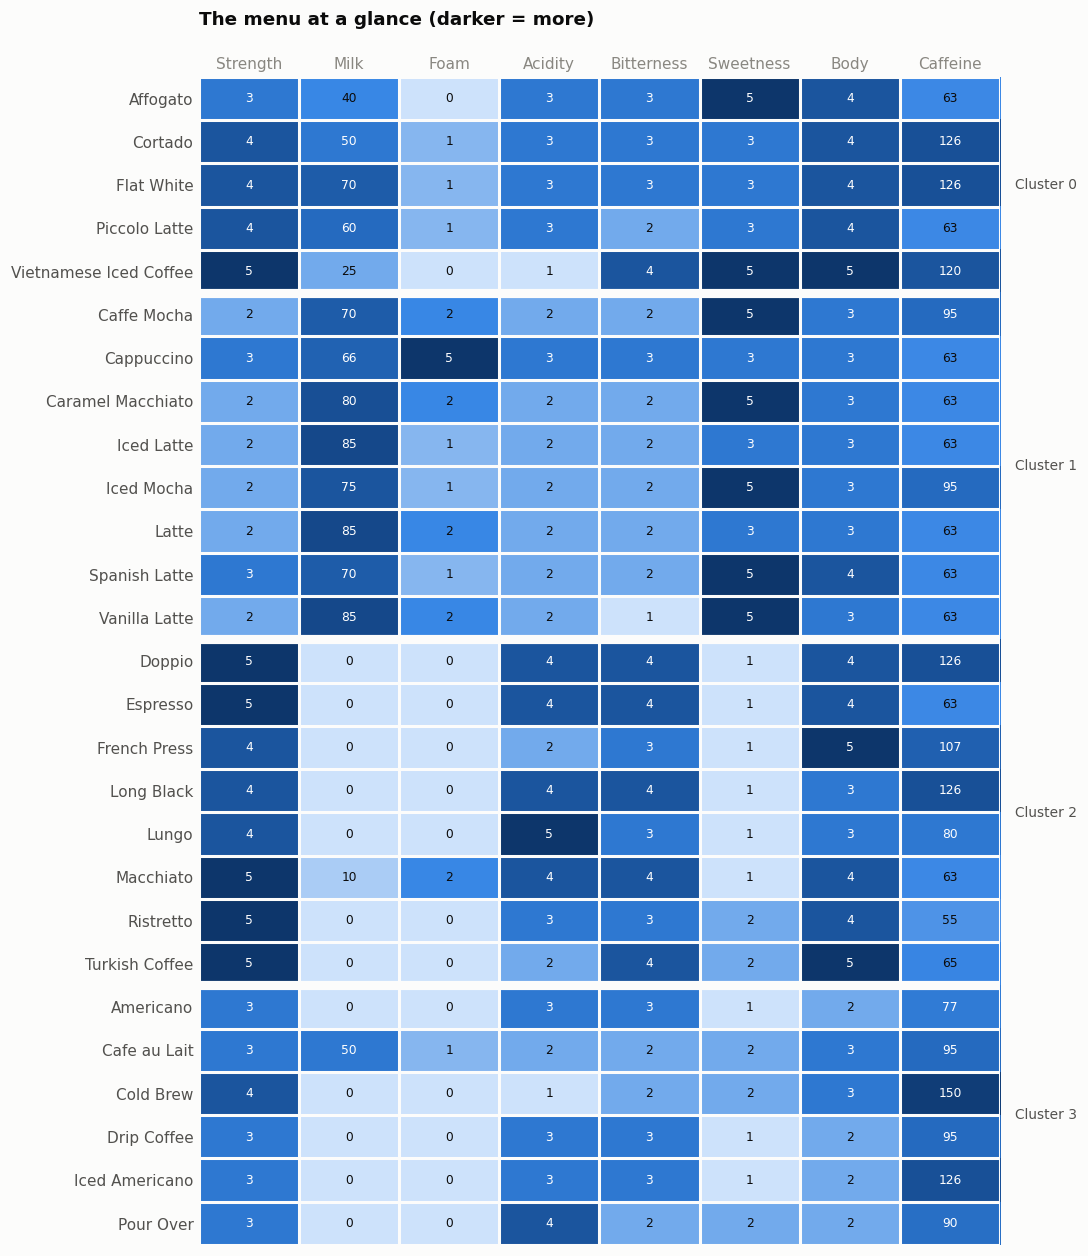

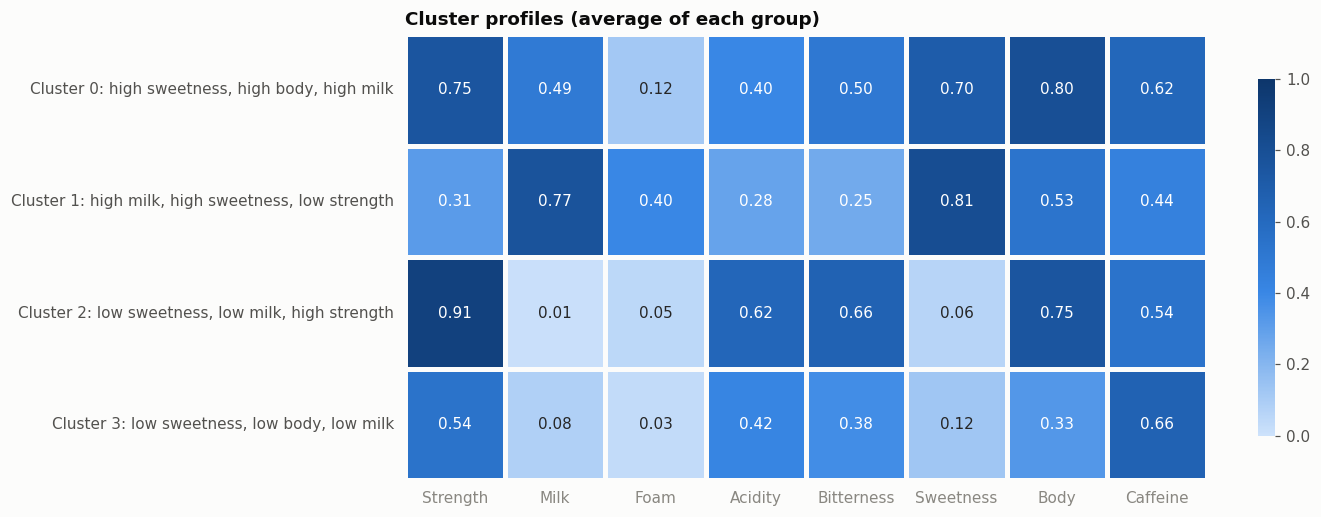

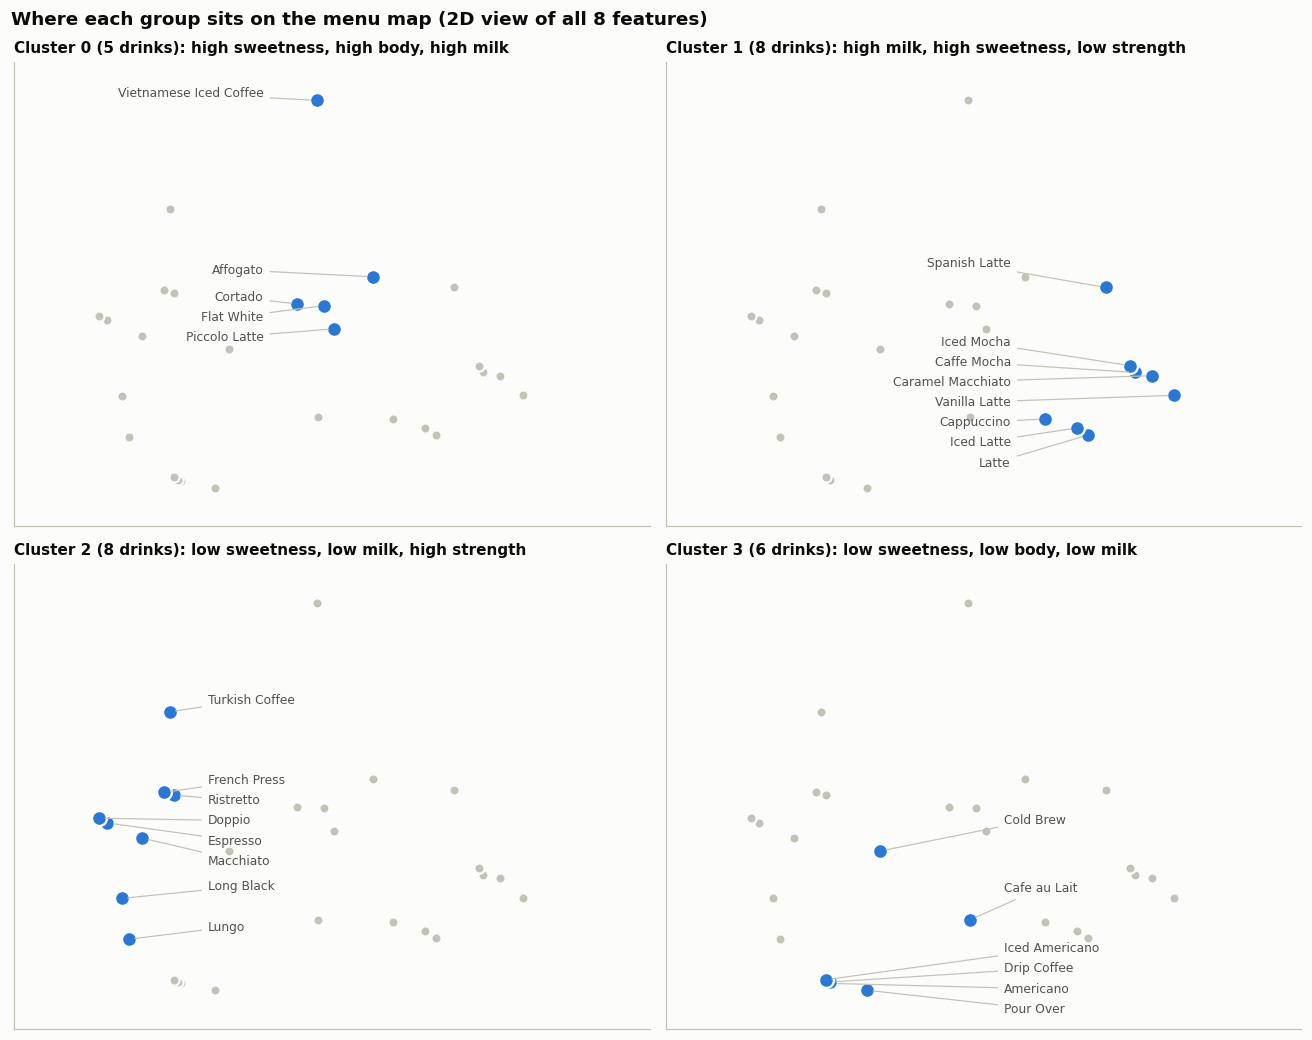

In [ ]:
def cluster_label(c):
    dev = pd.Series(cluster_centers[c], index=drink_features) - drinks_scaled.mean()
    top = dev.abs().sort_values(ascending=False).index[:3]
    return ", ".join(f"{'high' if dev[f] > 0 else 'low'} {FEATURE_LABELS[f].lower()}" for f in top)

def plot_menu_heatmap():
    order = drinks.sort_values(["cluster", "name"]).index
    data, raw = drinks_scaled.loc[order], drinks.loc[order, drink_features]
    n, m = len(order), len(drink_features)
    fig, ax = plt.subplots(figsize=(10, 0.36 * n + 1.8))
    ax.imshow(data.values, cmap=SEQ_CMAP, vmin=0, vmax=1, aspect="auto")
    ax.set_xticks(range(m))
    ax.set_xticklabels([FEATURE_LABELS[f] for f in drink_features])
    ax.xaxis.tick_top()
    ax.set_yticks(range(n))
    ax.set_yticklabels(drinks.loc[order, "name"])
    ax.grid(False)
    ax.set_xticks(np.arange(-.5, m), minor=True)
    ax.set_yticks(np.arange(-.5, n), minor=True)
    ax.grid(which="minor", color=SURFACE, linewidth=2)
    ax.tick_params(which="both", length=0)
    for r in range(n):
        for k in range(m):
            ax.text(k, r, f"{raw.iloc[r, k]:g}", ha="center", va="center",
                    fontsize=8, color=_text_on(data.iloc[r, k]))
    cl = drinks.loc[order, "cluster"].values
    for r in range(1, n):
        if cl[r] != cl[r - 1]:
            ax.axhline(r - 0.5, color=SURFACE, linewidth=6)
    for c in np.unique(cl):
        rows = np.where(cl == c)[0]
        ax.text(m - 0.35, rows.mean(), f"Cluster {c}", va="center", fontsize=9,
                color=INK2, clip_on=False)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.set_title("The menu at a glance (darker = more)", pad=34)
    show("menu_heatmap")

def plot_cluster_profiles():
    centers = pd.DataFrame(cluster_centers, columns=[FEATURE_LABELS[f] for f in drink_features])
    centers.index = [f"Cluster {c}: {cluster_label(c)}" for c in range(len(centers))]
    plt.figure(figsize=(13, 0.8 * len(centers) + 1.6))
    sns.heatmap(centers, annot=True, fmt=".2f", cmap=SEQ_CMAP, vmin=0, vmax=1,
                linewidths=2, linecolor=SURFACE, cbar_kws={"shrink": 0.8})
    plt.grid(False)
    plt.xticks(rotation=0)
    plt.title("Cluster profiles (average of each group)")
    show("cluster_profiles")

def _spread_labels(ax, pts, names, xr, yr, ylim, x_centre):
    order = np.argsort(-pts[:, 1])
    ys = pts[order, 1].astype(float)
    gap = 0.052 * yr
    for j in range(1, len(ys)):
        ys[j] = min(ys[j], ys[j - 1] - gap)
    ys += pts[order, 1].mean() - ys.mean()
    lo, hi = ylim[0] + gap, ylim[1] - gap
    if ys.max() > hi:
        ys -= ys.max() - hi
    if ys.min() < lo:
        ys += lo - ys.min()
    on_right = pts[:, 0].mean() <= x_centre
    lx = pts[:, 0].max() + 0.08 * xr if on_right else pts[:, 0].min() - 0.08 * xr
    for (px, py), ly, name in zip(pts[order], ys, np.array(names)[order]):
        ax.annotate(name, (px, py), xytext=(lx, ly), fontsize=8, color=INK2,
                    ha="left" if on_right else "right", va="center",
                    arrowprops=dict(arrowstyle="-", color=AXIS, linewidth=0.8,
                                    shrinkA=2, shrinkB=4))

def plot_cluster_panels():
    coords = PCA(n_components=2, random_state=42).fit_transform(X)
    xr, yr = np.ptp(coords[:, 0]), np.ptp(coords[:, 1])
    n, cols = OPTIMAL_K, 2
    rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(12, 4.8 * rows), sharex=True, sharey=True)
    flat = np.ravel(axes)
    for c, ax in zip(range(n), flat):
        mine = (drinks["cluster"] == c).values
        ax.scatter(coords[~mine, 0], coords[~mine, 1], s=45, color=DIM,
                   edgecolor=SURFACE, linewidth=1.5, zorder=2)
        ax.scatter(coords[mine, 0], coords[mine, 1], s=95, color=BLUE,
                   edgecolor=SURFACE, linewidth=1.5, zorder=3)
        ylim = (coords[:, 1].min() - 0.1 * yr, coords[:, 1].max() + 0.1 * yr)
        ax.set_xlim(coords[:, 0].min() - 0.2 * xr, coords[:, 0].max() + 0.3 * xr)
        ax.set_ylim(*ylim)
        _spread_labels(ax, coords[mine], drinks.loc[mine, "name"].tolist(), xr, yr,
                       ylim, coords[:, 0].mean())
        ax.set_title(f"Cluster {c} ({mine.sum()} drinks): {cluster_label(c)}", fontsize=10)
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for ax in flat[n:]:
        ax.axis("off")
    fig.suptitle("Where each group sits on the menu map (2D view of all 8 features)",
                 x=0.01, ha="left", fontsize=12, fontweight="bold")
    show("cluster_panels")

plot_menu_heatmap()
plot_cluster_profiles()
plot_cluster_panels()

### 7. Recommender Engine Logic

In [ ]:
def _apply_filters(frame, temperature=None, max_caffeine=None, no_milk=False,
                   categories=None):
    mask = pd.Series(True, index=frame.index)
    if temperature:
        mask &= frame["temperature"].isin([temperature, "hot-cold"])
    if max_caffeine is not None:
        mask &= frame["caffeine_mg"] <= max_caffeine
    if no_milk:
        mask &= frame["milk_pct"] == 0
    if categories:
        mask &= frame["category"].isin(categories)
    return mask

def _weighted_distance(scaled_frame, target, weights, cols):
    w = pd.Series({f: (weights or {}).get(f, 1.0) for f in cols})
    diff = scaled_frame[cols] - target[cols]
    return np.sqrt((w * diff ** 2).sum(axis=1) / w.sum())

def recommend_drinks(prefs, weights=None, top_n=5, within_cluster=False,
                     **filters):
    unknown = set(prefs) - set(drink_features)
    if unknown:
        raise ValueError(f"Unknown preference(s): {sorted(unknown)}")
    given = [f for f in drink_features if f in prefs]
    if not given:
        raise ValueError("Give at least one drink preference.")

    user = scale_drink_values(pd.DataFrame([{f: prefs[f] for f in given}])).iloc[0]

    out = drinks.copy()
    out["distance"] = _weighted_distance(drinks_scaled, user, weights, given)
    out["similarity"] = 1 - out["distance"]

    mask = _apply_filters(out, **filters)
    if within_cluster:
        idx = [drink_features.index(f) for f in given]
        centers = pd.DataFrame(cluster_centers[:, idx], columns=given)
        w = np.array([(weights or {}).get(f, 1.0) for f in given])
        d = np.sqrt((w * (centers - user[given]) ** 2).sum(axis=1) / w.sum())
        nearest = int(d.values.argmin())
        in_cluster = mask & (out["cluster"] == nearest)
        if in_cluster.sum() >= top_n:
            mask = in_cluster

    out = out[mask].sort_values("similarity", ascending=False)
    return out[["name", "category", "temperature"] + given + ["similarity"]].head(top_n)

def similar_drinks(drink_name, weights=None, top_n=5, **filters):
    match = drinks.index[drinks["name"].str.lower() == drink_name.lower()]
    if len(match) == 0:
        close = drinks["name"][drinks["name"].str.contains(drink_name, case=False)].tolist()
        raise ValueError(f"'{drink_name}' not on the menu. Did you mean: {close or drinks['name'].tolist()}")
    i = match[0]

    out = drinks.copy()
    out["distance"] = _weighted_distance(drinks_scaled, drinks_scaled.loc[i],
                                         weights, drink_features)
    out["similarity"] = 1 - out["distance"]

    mask = _apply_filters(out, **filters) & (out.index != i)
    out = out[mask].sort_values("similarity", ascending=False)
    return out[["name", "category", "temperature", "flavor_notes", "similarity"]].head(top_n)

### 8. Recommendation Visualization Helpers

In [ ]:
def plot_recommendations(picks, title, filename="recommendations"):
    p = picks.iloc[::-1]
    fig, ax = plt.subplots(figsize=(8, 0.55 * len(p) + 1.4))
    ax.barh(p["name"], p["similarity"], height=0.55, color=BLUE)
    for y, v in enumerate(p["similarity"]):
        ax.text(v + 0.015, y, f"{v:.2f}", va="center", fontsize=9, color=INK2)
    ax.set_xlim(0, 1.12)
    ax.set_xlabel("Match (1.00 = identical to the request)")
    ax.set_title(title)
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", length=0)
    show(filename)

def plot_request_vs_drink(prefs, drink_name, filename="request_vs_drink"):
    feats = [f for f in drink_features if f in prefs]
    req = scale_drink_values(pd.DataFrame([{f: prefs[f] for f in feats}])).iloc[0]
    row = drinks_scaled.loc[drinks["name"] == drink_name, feats].iloc[0]
    y, h = np.arange(len(feats)), 0.34
    fig, ax = plt.subplots(figsize=(8, 0.6 * len(feats) + 1.8))
    ax.barh(y - h / 2, req.values, height=h, color=BLUE, edgecolor=SURFACE,
            linewidth=1.5, label="Your request")
    ax.barh(y + h / 2, row.values, height=h, color=ORANGE, edgecolor=SURFACE,
            linewidth=1.5, label=drink_name)
    ax.set_yticks(y)
    ax.set_yticklabels([FEATURE_LABELS[f] for f in feats])
    ax.invert_yaxis()
    ax.set_xlim(0, 1)
    ax.set_xlabel("Scaled 0-1 (low to high)")
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", length=0)
    ax.legend(frameon=False, ncol=2, loc="upper left", bbox_to_anchor=(0, -0.2))
    ax.set_title(f"Your request vs {drink_name}")
    show(filename)

def recommend(prefs, top_n=3, plot=True, **kwargs):
    picks = recommend_drinks(prefs, top_n=top_n, **kwargs)
    if picks.empty:
        print("No drinks match those filters.")
        return picks
    notes = drinks.set_index("name")["flavor_notes"]
    for _, r in picks.iterrows():
        print(f"{r['name']:<24} match {r['similarity']:.2f}   {notes[r['name']]}")
    if plot:
        plot_recommendations(picks, "Top picks for your request")
        plot_request_vs_drink(prefs, picks.iloc[0]["name"])
    return picks

### 9. Execution Tests & Sanity Checks


--- Sweet, milky, mild, hot ---
Caramel Macchiato        match 1.00   layered, sweet caramel, vanilla
Vanilla Latte            match 0.98   sweet vanilla, creamy, dessert-like
Caffe Mocha              match 0.95   chocolate and espresso, rich, sweet


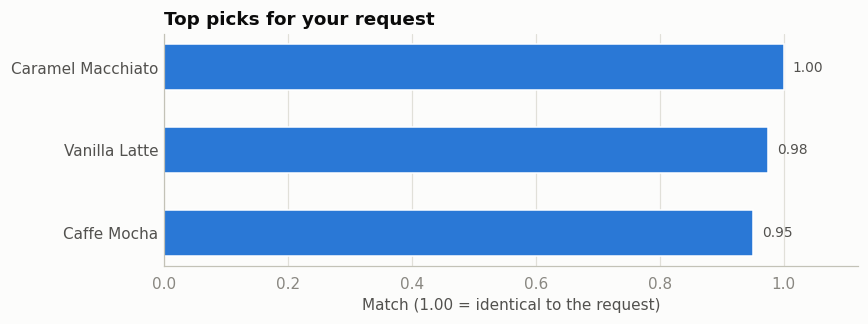

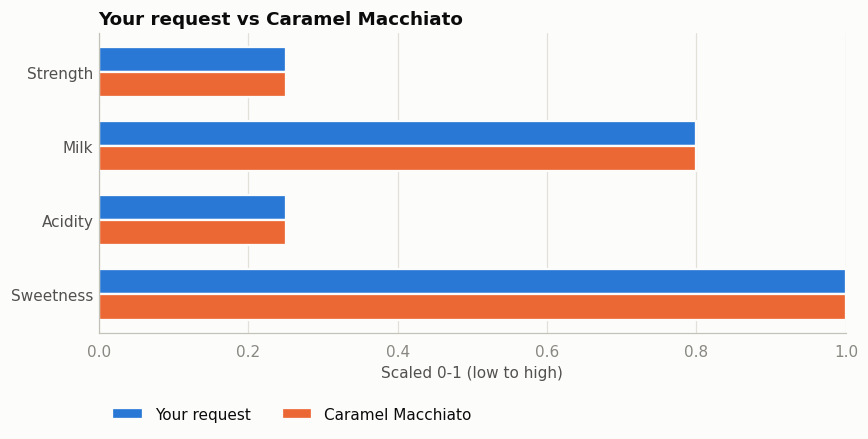


--- Strong black, no milk ---
Espresso                 match 1.00   intense, caramelised, lingering finish
Doppio                   match 1.00   intense, heavy, bittersweet
Ristretto                match 0.88   concentrated, sweeter and less bitter than espresso

--- Dairy-free, iced, bright, low caffeine ---
Iced Americano           match 0.80   refreshing, crisp, roasty

--- Similar to Flat White ---
         name  category temperature                             flavor_notes  similarity
      Cortado  espresso         hot balanced, espresso softened by warm milk       0.929
Piccolo Latte  espresso         hot              small, concentrated, creamy       0.831
 Cafe au Lait      milk         hot    drip coffee with steamed milk, mellow       0.779
Spanish Latte flavoured         hot        condensed milk, very sweet, silky       0.728


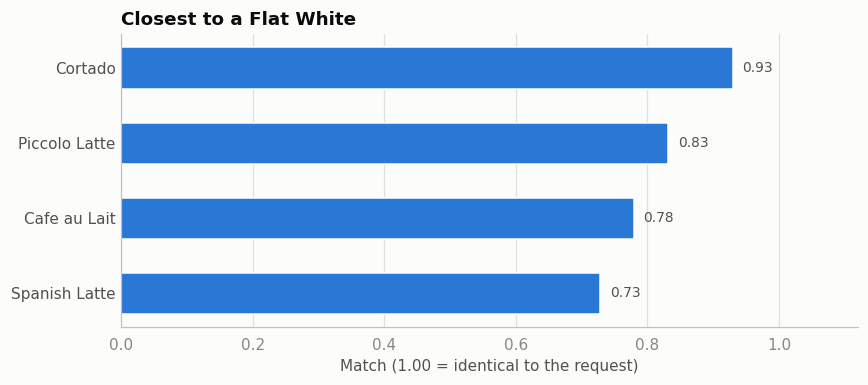


--- Similar to Iced Latte, but hot ---
             name  category temperature                          flavor_notes  similarity
            Latte      milk         hot    creamy, milky, mild coffee flavour       0.929
     Cafe au Lait      milk         hot drip coffee with steamed milk, mellow       0.810
Caramel Macchiato flavoured         hot       layered, sweet caramel, vanilla       0.809
    Vanilla Latte flavoured         hot   sweet vanilla, creamy, dessert-like       0.790

=== Sanity checks (top-3 categories should fall in expected set) ===
[PASS] sweet milky mild: ['Caramel Macchiato', 'Vanilla Latte', 'Iced Mocha']
[PASS] strong, no milk, bitter: ['Espresso', 'Doppio', 'Macchiato']
[PASS] foamy, medium milk (foam weighted x3): ['Cappuccino', 'Caffe Mocha', 'Caramel Macchiato']


In [ ]:
print("\n--- Sweet, milky, mild, hot ---")
recommend({"strength": 2, "milk_pct": 80, "sweetness": 5, "acidity": 2},
          temperature="hot")

print("\n--- Strong black, no milk ---")
recommend({"strength": 5, "milk_pct": 0, "sweetness": 1, "body": 4}, no_milk=True,
          plot=False)

print("\n--- Dairy-free, iced, bright, low caffeine ---")
recommend({"strength": 3, "acidity": 4, "sweetness": 2},
          temperature="iced", no_milk=True, max_caffeine=130, plot=False)

print("\n--- Similar to Flat White ---")
sim = similar_drinks("Flat White", top_n=4)
print(sim.round(3).to_string(index=False))
plot_recommendations(sim, "Closest to a Flat White", "similar_flat_white")

print("\n--- Similar to Iced Latte, but hot ---")
print(similar_drinks("Iced Latte", temperature="hot", top_n=4).round(3).to_string(index=False))

# Sanity checks
checks = [
    ("sweet milky mild",
     {"strength": 2, "milk_pct": 80, "sweetness": 5},
     {"flavoured", "milk"}),
    ("strong, no milk, bitter",
     {"strength": 5, "milk_pct": 0, "bitterness": 4, "sweetness": 1},
     {"espresso", "black"}),
    ("foamy, medium milk (foam weighted x3)",
     {"strength": 3, "milk_pct": 66, "foam_level": 5},
     {"milk", "flavoured"},
     {"foam_level": 3}),
]
print("\n=== Sanity checks (top-3 categories should fall in expected set) ===")
for label, prefs, expected, *opt in checks:
    top = recommend_drinks(prefs, weights=opt[0] if opt else None, top_n=3)
    ok = set(top["category"]) <= expected
    print(f"[{'PASS' if ok else 'CHECK'}] {label}: {top['name'].tolist()}")